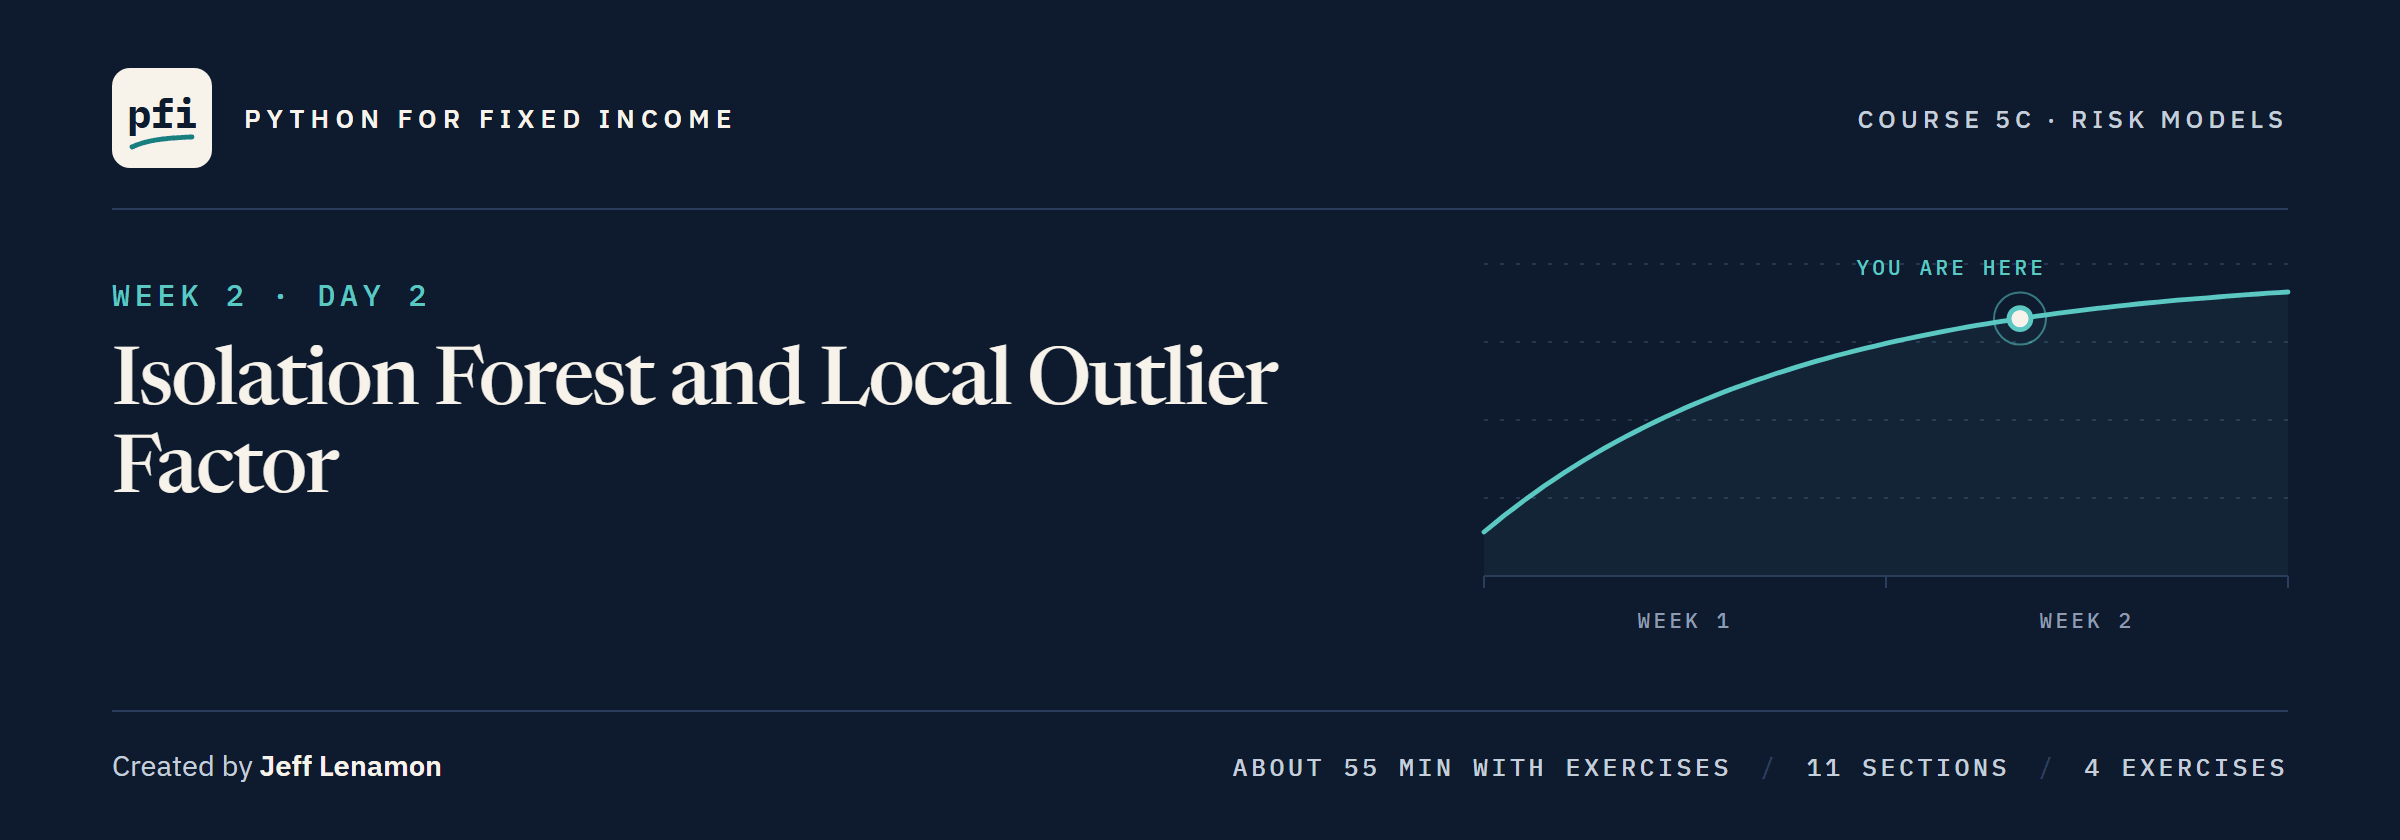

# Isolation Forest and Local Outlier Factor

Week 2, Day 2. Screen the curve's days and the book's records for rows that are unusual in how their columns sit together, and score three screens on labels they never saw.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `holdings.csv`, the course's book of 200 bonds as of 2026-09-30, with `ratings.csv` for the rating scale: **synthetic**, invented issuers and CUSIPs, no real company.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week2/day2/07_isolation_forest_and_local_outlier_factor.ipynb)

# Problem Statement

## Business Context

A risk team screens two things it leans on: the curve's daily moves and the book's own fields.
For the curve it reads the 2, 5, 10 and 30 Yr daily changes over the development years, 2015 to 2022; the held-out years stay closed for the capstone.
A flagged day is a day the daily changes were unusual together, listed as history.
For the book, 12 field errors are planted in a copy with a seeded generator, shown and labelled planted, and the labels are used only to score.
A flagged bond is a record to check, never mispriced, rich or cheap.
Every threshold and every `contamination` is written down before a label is read.

## Objectives

Measure a squared Mahalanobis distance by hand with a covariance matrix and its inverse, and set a chi-squared cutoff for it.
Fit a classical and a robust covariance yardstick on curve days, and list the unusual days as history.
Plant field errors in a copy of the book.
Isolate a bond with random cuts, and read an isolation forest's score and its settings.
Read a local outlier factor from a bond's neighbours.
Score screens against planted labels and on the untouched book, and set `contamination` without the labels.

## Data Dictionary

`treasury_par_yields.csv`, one row per trading day (the columns used today):

1. `date`: the trading day
2. `2 Yr`, `5 Yr`, `10 Yr`, `30 Yr`: par yields, percent

`holdings.csv`, one row per bond (the columns used today):

1. `cusip`, `issuer`, `rating`: the bond, its issuer (both invented) and its rating
2. `coupon`: the coupon, percent a year
3. `maturity`, `as_of_date`: the dates that give its years to maturity
4. `price`: the clean price, per 100 face
5. `oas`: the option-adjusted spread, bp
6. `duration`: modified duration, years

Made here: `changes` (bp a day), `years_to_maturity`, `log_oas`, `planted`, `scaled` (robust z), the scores and the flags.

## Your Route Through Day 2

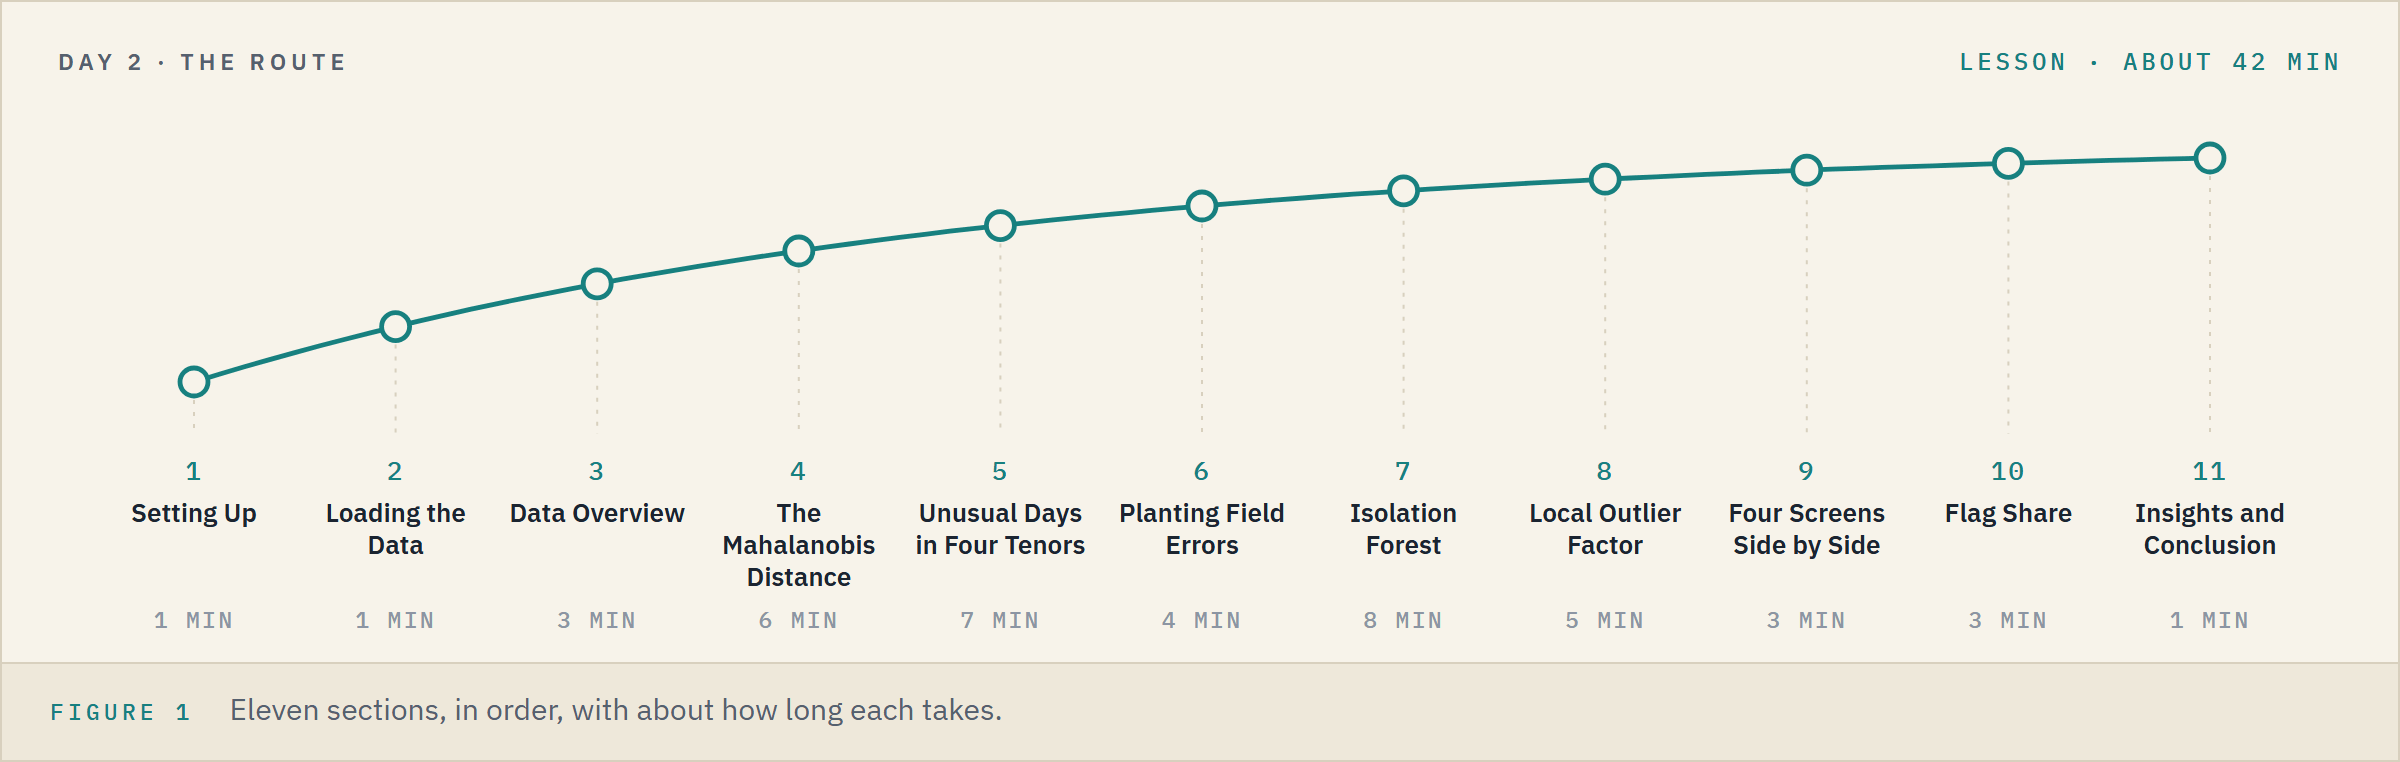

**Time.** About 42 minutes for the lesson, then about 12 for the four exercises.

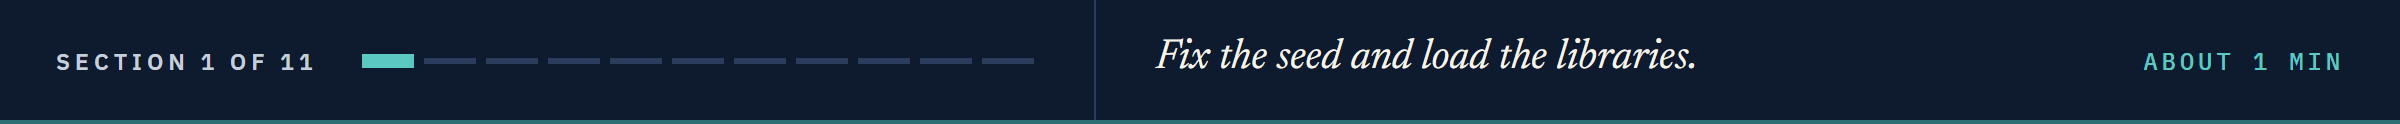

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# the chi-squared curve's percentiles
from scipy import stats

# the screens: a covariance yardstick (classical and robust), a forest of random cuts, and neighbours
from sklearn.covariance import EmpiricalCovariance, MinCovDet
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors

# to score a screen against the planted labels
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
# one colour for each of the four kinds of row a confusion matrix counts
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}
plt.rcParams["figure.figsize"] = (10, 5)

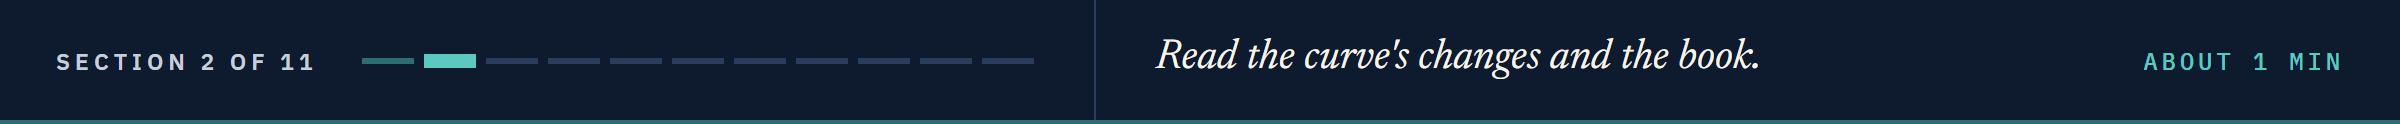

# Loading the Data

## The Curve's Development Years

`CUT` is Course 5B's Day 2 cut, and the changes are Day 2's 2,000 days.

In [3]:
# the Treasury par yields (percent), one row per trading day, and the four tenors read today
curve = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")
TENORS = ["2 Yr", "5 Yr", "10 Yr", "30 Yr"]

# each day's change in bp over the development years; the held-out rows are counted and never read
CUT = "2022-12-30"
changes = (curve.loc[:CUT, TENORS].diff() * 100).iloc[1:]
print(len(changes), "days, from", changes.index[0].date(), "to", changes.index[-1].date(), "| held-out rows:", len(curve) - len(curve.loc[:CUT]))
print("Every change a whole number of bp:", np.allclose(changes, changes.round()))

2000 days, from 2015-01-05 to 2022-12-30 | held-out rows: 939
Every change a whole number of bp: True


The file's yields carry two decimals, so every change is a whole number of bp.

## The Book

In [4]:
# the book of 200 synthetic bonds as of 2026-09-30, and years to maturity as on Day 2
book = pd.read_csv(DATA + "holdings.csv")
book["years_to_maturity"] = (pd.to_datetime(book["maturity"]) - pd.to_datetime(book["as_of_date"])).dt.days / 365.25
print(book.shape, "| repeated CUSIPs:", book["cusip"].duplicated().sum(), "| blanks:", book.isna().sum().sum())

(200, 20) | repeated CUSIPs: 0 | blanks: 0


**The curve tells us about days, the book about records; both start clean.**

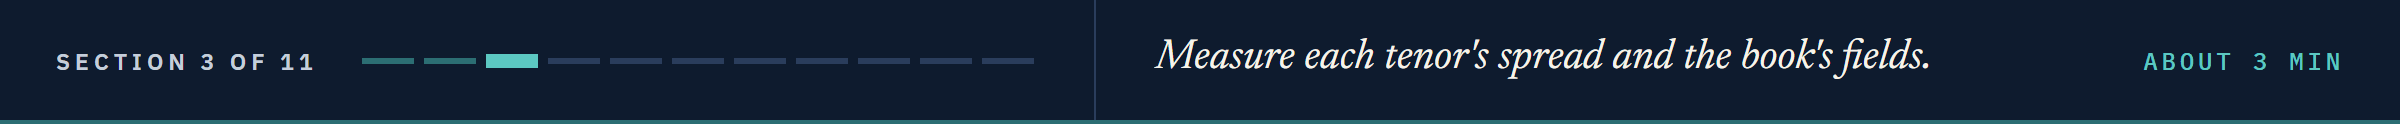

# Data Overview

## The Four Tenors' Daily Changes

In [5]:
# each tenor's daily change in bp
changes.describe().round(2)

,2 Yr,5 Yr,10 Yr,30 Yr
count,2000.00,2000.00,2000.00,2000.00
mean,0.19,0.12,0.09,0.06
std,4.19,4.96,5.03,4.96
min,-27.00,-32.00,-30.00,-31.00
25%,-2.00,-3.00,-3.00,-3.00
50%,0.00,0.00,0.00,0.00
75%,2.00,3.00,3.00,3.00
max,34.00,31.00,29.00,29.00


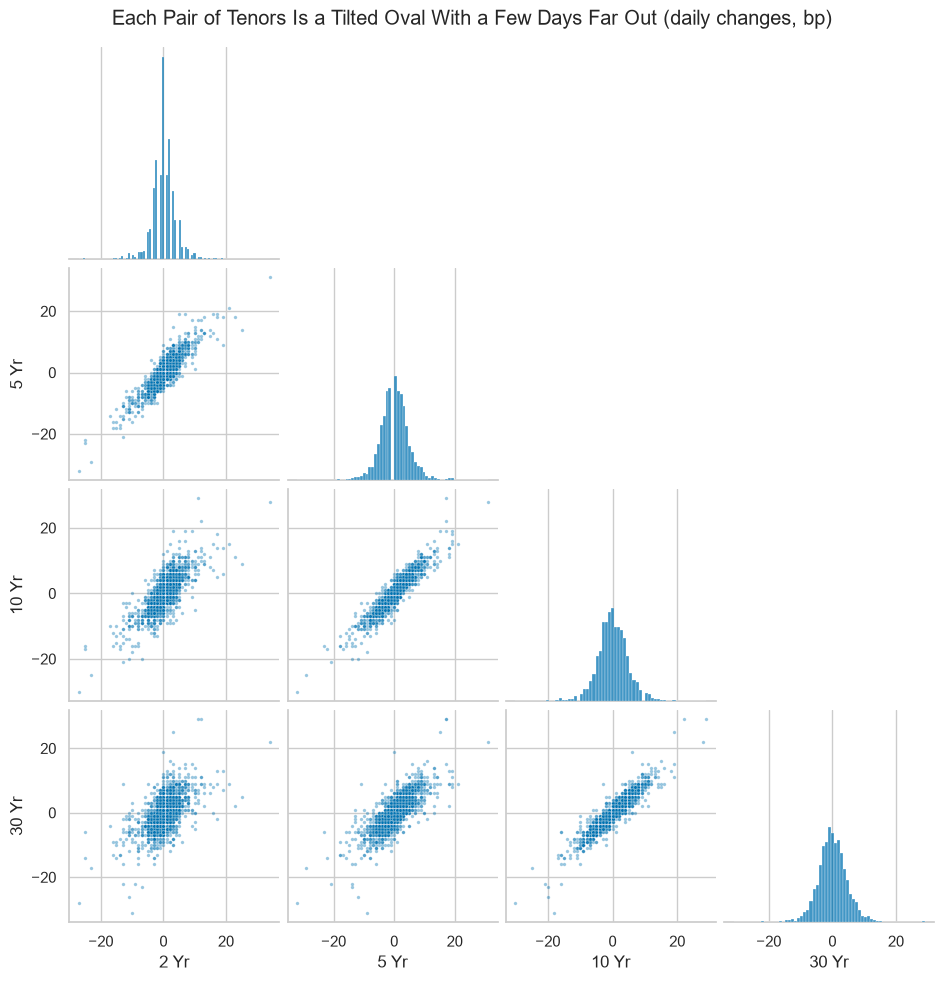

In [6]:
# every pair of tenors against each other, and each tenor's histogram
pairs = sns.pairplot(changes, corner=True, plot_kws={"s": 6, "alpha": 0.4}, height=2.4)
pairs.figure.suptitle("Each Pair of Tenors Is a Tilted Oval With a Few Days Far Out (daily changes, bp)", y=1.02)
plt.show()

In [7]:
# how closely each pair of tenors moved together
changes.corr().round(3)

,2 Yr,5 Yr,10 Yr,30 Yr
2 Yr,1.000,0.883,0.755,0.583
5 Yr,0.883,1.000,0.932,0.785
10 Yr,0.755,0.932,1.000,0.927
30 Yr,0.583,0.785,0.927,1.000


Each cloud is a tilted oval: the tenors moved together, the 5 Yr and 10 Yr most closely (0.932) and the 2 Yr and 30 Yr least (0.583).

## The Book's Fields

In [8]:
# duration against years to maturity, OAS's skew before and after a log, and the five fields the screens read
print("Duration over years to maturity:", round((book["duration"] / book["years_to_maturity"]).min(), 3), "to", round((book["duration"] / book["years_to_maturity"]).max(), 3))
print("OAS skew:", round(book["oas"].skew(), 2), "| skew of its log:", round(np.log(book["oas"]).skew(), 2))
book[["coupon", "price", "oas", "duration", "years_to_maturity"]].describe().round(2)

Duration over years to maturity: 0.38 to 0.955
OAS skew: 3.93 | skew of its log: 0.34


,coupon,price,oas,duration,years_to_maturity
count,200.00,200.00,200.00,200.00,200.00
mean,5.94,98.83,185.75,6.47,9.85
std,1.65,7.40,193.95,3.35,7.33
min,3.25,62.04,19.00,0.93,1.00
25%,4.75,95.14,81.75,3.88,4.42
50%,5.69,99.42,135.50,6.31,8.29
75%,6.88,103.00,213.00,8.14,11.38
max,11.00,119.13,1551.00,16.04,29.90


No duration is longer than its maturity.

OAS runs from 19 to 1,551 bp with a long right tail; its log is close to symmetric, so the screens read the log.

**A day or a bond is several numbers at once, and the numbers lean on each other.**

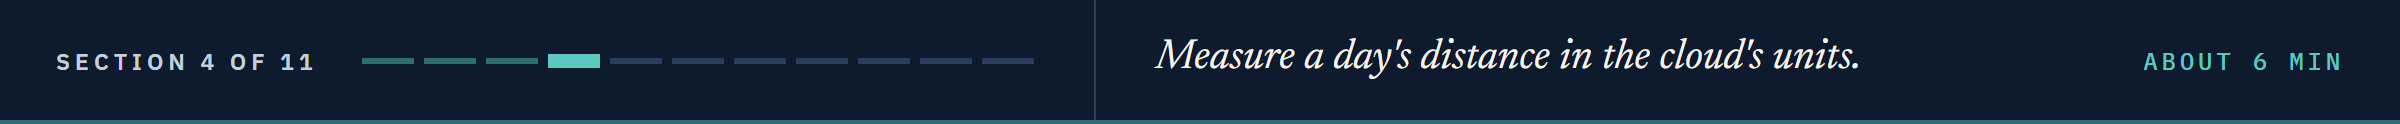

# The Mahalanobis Distance

## Two Days the Same Distance Apart

The straight-line distance of Course 4's Day 12 measures a day's distance from the average day in bp.

In [9]:
# the 2 Yr and 10 Yr changes, their average day, and two days' straight-line distance from it
two = changes[["2 Yr", "10 Yr"]]
centre = two.mean()
for day in ["2022-07-13", "2016-03-01"]:
    gap = two.loc[day] - centre
    print(day, "| 2 Yr", f"{two.loc[day, '2 Yr']:+.0f}", "| 10 Yr", f"{two.loc[day, '10 Yr']:+.0f}", "| distance (bp):", round(np.sqrt((gap ** 2).sum()), 2))

2022-07-13 | 2 Yr +10 | 10 Yr -5 | distance (bp): 11.05
2016-03-01 | 2 Yr +7 | 10 Yr +9 | distance (bp): 11.22


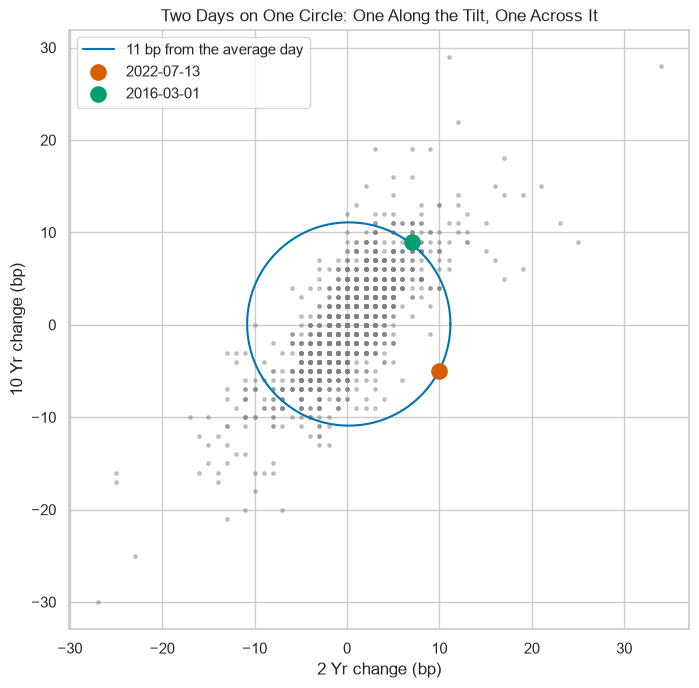

In [10]:
# the 2 Yr against the 10 Yr, the two days marked, and a circle 11 bp from the average day (Day 3's equal axes)
theta = np.linspace(0, 2 * np.pi, 361)
circle = np.column_stack([np.cos(theta), np.sin(theta)])  # Day 3's unit circle
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(two["2 Yr"], two["10 Yr"], s=6, color="gray", alpha=0.4)
ax.plot(centre["2 Yr"] + 11 * circle[:, 0], centre["10 Yr"] + 11 * circle[:, 1], color="C0", label="11 bp from the average day")
for day, colour in [("2022-07-13", "C3"), ("2016-03-01", "C2")]:
    ax.scatter(two.loc[day, "2 Yr"], two.loc[day, "10 Yr"], s=120, color=colour, label=day, zorder=3)
ax.set_aspect("equal")
ax.set(xlabel="2 Yr change (bp)", ylabel="10 Yr change (bp)", title="Two Days on One Circle: One Along the Tilt, One Across It")
ax.legend(loc="upper left")
plt.show()

In bp the two days tie.

2016-03-01 moved both tenors up, along the cloud's tilt; 2022-07-13 moved them apart, across it.

The **Mahalanobis distance** measures a day's distance from the average day in units of the cloud's own spread, along its tilt and across it.

**Predict 1**

Both days sit about 11 bp from the average day.

Q. In squared Mahalanobis distance, how many times farther is 2022-07-13 than 2016-03-01? Write down a number.

## The Covariance Matrix and Its Inverse

The **covariance matrix** holds each tenor's variance on its diagonal and each pair's covariance (Course 4's Day 11) off it, in bp squared.
`np.cov(two, rowvar=False)` builds it from columns, and `np.linalg.inv` gives its **inverse**, the matrix that multiplies it back to the identity, `np.eye(2)` (Course 1).
The **squared Mahalanobis distance** of a gap `x` from the average day is then `x @ inv @ x` (Course 1's `@`).

In [11]:
# the covariance matrix, its inverse, and the check that one undoes the other (Day 2's np.allclose)
S = np.cov(two, rowvar=False)
inv = np.linalg.inv(S)
print(S.round(2))
print(inv.round(4))
print("S @ inv is the identity:", np.allclose(S @ inv, np.eye(2)))

[[17.56 15.9 ]
 [15.9  25.29]]
[[ 0.1323 -0.0832]
 [-0.0832  0.0919]]
S @ inv is the identity: True


In [12]:
# each day's gap from the average day, through the inverse
x_far = (two.loc["2022-07-13"] - centre).to_numpy()
x_near = (two.loc["2016-03-01"] - centre).to_numpy()
far, near = x_far @ inv @ x_far, x_near @ inv @ x_near
print("2022-07-13:", round(far, 2), "| 2016-03-01:", round(near, 2), "| ratio:", round(far / near, 1))

2022-07-13: 23.42 | 2016-03-01: 3.33 | ratio: 7.0


### Interpretation of the Squared Distance

The same 11 bp is 7.0 times farther across the tilt than along it.

The inverse divides by each tenor's spread and undoes the correlation, so a move the tenors seldom make counts for more.

## Every Day at Once

In [13]:
# all 2,000 days at once: each gap times the inverse, times the gap again, summed across the row
gaps = (two - centre).to_numpy()
d2_hand = pd.Series(((gaps @ inv) * gaps).sum(axis=1), index=two.index)

# scikit-learn's classical yardstick: the mean and the covariance of every day
classical2 = EmpiricalCovariance().fit(two)
print("By hand:", d2_hand[["2022-07-13", "2016-03-01"]].round(2).tolist())
print("EmpiricalCovariance:", classical2.mahalanobis(two.loc[["2022-07-13", "2016-03-01"]]).round(2).tolist())

By hand: [23.42, 3.33]
EmpiricalCovariance: [23.43, 3.34]


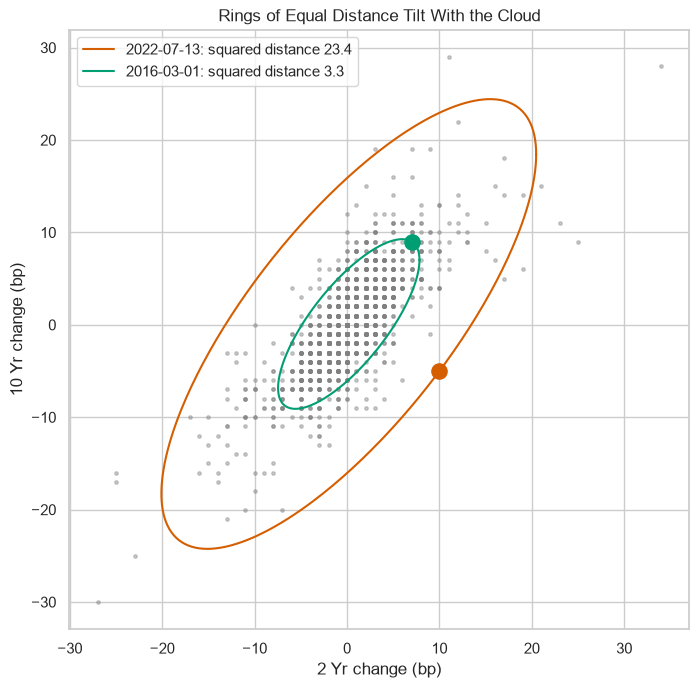

In [14]:
# rings of equal squared distance through each day: Day 3's circle pushed through the Cholesky factor
L = np.linalg.cholesky(S)
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(two["2 Yr"], two["10 Yr"], s=6, color="gray", alpha=0.4)
for day, d2_day, colour in [("2022-07-13", far, "C3"), ("2016-03-01", near, "C2")]:
    ring = centre.to_numpy() + np.sqrt(d2_day) * circle @ L.T
    ax.plot(ring[:, 0], ring[:, 1], color=colour, label=f"{day}: squared distance {d2_day:.1f}")
    ax.scatter(two.loc[day, "2 Yr"], two.loc[day, "10 Yr"], s=120, color=colour, zorder=3)
ax.set_aspect("equal")
ax.set(xlabel="2 Yr change (bp)", ylabel="10 Yr change (bp)", title="Rings of Equal Distance Tilt With the Cloud")
ax.legend(loc="upper left")
plt.show()

`.mahalanobis()` returns the squared distance, and from here on it gives every one.

`EmpiricalCovariance` divides by n where `np.cov` divides by n - 1, so its squared distances sit 1 part in 2,000 higher.

Every point on a ring is equally far from the average day; the tilt is the correlation.

## A Cutoff for a Squared Distance

For normal rows the squared distance follows the chi-squared distribution with one degree of freedom per column, so Course 5B's Day 4 `stats.chi2.ppf` sets a cutoff.

In [15]:
# the 0.999 cutoff for two tenors and for four
cut_two = stats.chi2.ppf(0.999, 2)
cut_four = stats.chi2.ppf(0.999, 4)
print("Two tenors:", round(cut_two, 2), "| four tenors:", round(cut_four, 2))
print("2022-07-13's", round(far, 2), "sits beyond the two-tenor cutoff")

Two tenors: 13.82 | four tenors: 18.47
2022-07-13's 23.42 sits beyond the two-tenor cutoff


**Distance in units of the data's own spread and correlation, with a cutoff from the chi-squared.**

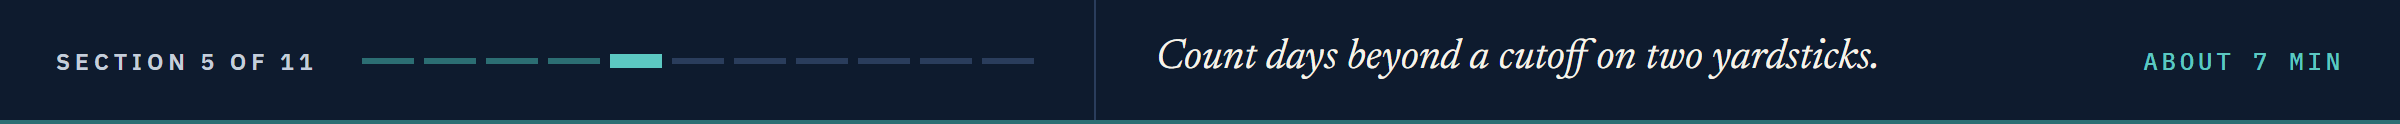

# Unusual Days in Four Tenors

**Predict 2**

At the 0.999 cutoff, about 2 of 2,000 normal days would pass.

Q. How many of the 2,000 days pass it in four tenors, with the classical yardstick? Write down a number.

## The Classical Yardstick

In [16]:
# the classical yardstick on four tenors; distances rounded to 6 places before any count (Course 3's notebook 06)
classical = EmpiricalCovariance().fit(changes)
d2_classical = pd.Series(classical.mahalanobis(changes), index=changes.index).round(6)
print(f"Days beyond {cut_four:.2f}:", (d2_classical > cut_four).sum(), "| normal days would give about", 2000 * 0.001)

Days beyond 18.47: 44 | normal days would give about 2.0


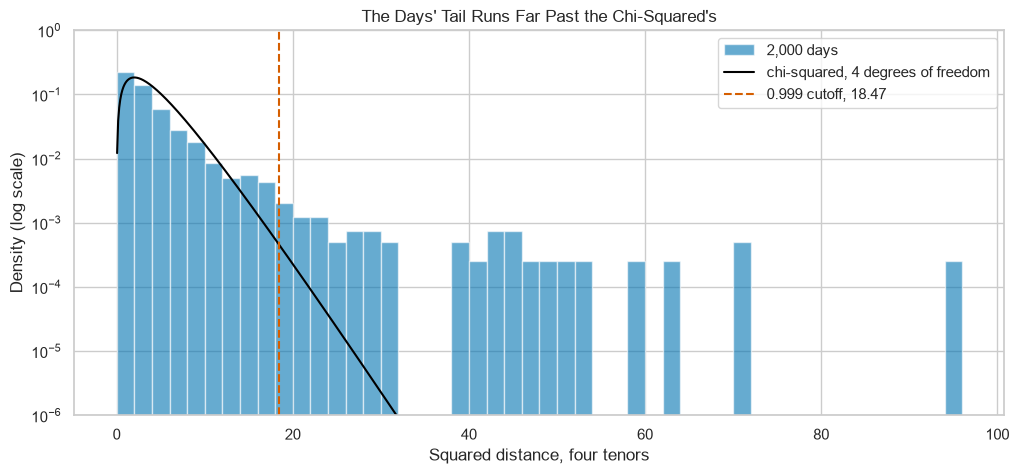

In [17]:
# the squared distances against the chi-squared density with 4 degrees of freedom, on a log axis
x = np.linspace(0.05, d2_classical.max(), 800)
plt.figure(figsize=(12, 5))
plt.hist(d2_classical, bins=np.arange(0, d2_classical.max() + 2, 2), density=True, alpha=0.6, label="2,000 days")
plt.plot(x, stats.chi2.pdf(x, 4), color="black", label="chi-squared, 4 degrees of freedom")
plt.axvline(cut_four, color="C3", linestyle="--", label=f"0.999 cutoff, {cut_four:.2f}")
plt.yscale("log")
plt.ylim(1e-6, 1)
plt.xlabel("Squared distance, four tenors")
plt.ylabel("Density (log scale)")
plt.title("The Days' Tail Runs Far Past the Chi-Squared's")
plt.legend()
plt.show()

The daily changes carry fat tails (Course 5B's Day 7), so the cutoff still ranks the days but its count is no promise.

## The Robust Covariance

The classical mean and covariance are built from every day, the unusual ones included: does Day 6's masking reach several columns?
scikit-learn's robust yardstick is `MinCovDet`, short for minimum covariance determinant, and it does not use every day.
It finds the **core**, the set of about half the days whose ellipse is the most tightly packed, takes their centre and covariance, then keeps every day within a chi-squared cutoff of that core and refits.
`random_state=SEED` fixes its random starts.

**Predict 3**

The classical rings tilt with the 2 Yr and 10 Yr cloud.

Q. Sketch the robust 0.999 ellipse beside the classical one on the same cloud.

## Two Ellipses on One Cloud

In [18]:
# the robust yardstick on the 2 Yr and 10 Yr (.support_ marks the core days), and the days outside each 0.999 ellipse
robust2 = MinCovDet(random_state=SEED).fit(two)
outside_classical = classical2.mahalanobis(two).round(6) > cut_two
outside_robust = robust2.mahalanobis(two).round(6) > cut_two
print("Core:", robust2.support_.sum(), "days | outside classical:", outside_classical.sum(), "| outside robust:", outside_robust.sum(), "| outside both:", (outside_classical & outside_robust).sum())

# each yardstick's sd per tenor (bp) and its correlation, from its covariance_ (its centre is location_)
compare = pd.DataFrame({fit_name: [np.sqrt(fit.covariance_[0, 0]), np.sqrt(fit.covariance_[1, 1]), fit.covariance_[0, 1] / np.sqrt(fit.covariance_[0, 0] * fit.covariance_[1, 1])]
                        for fit_name, fit in [("classical", classical2), ("robust", robust2)]}, index=["2 Yr sd", "10 Yr sd", "correlation"])
compare.round(3)

Core: 1787 days | outside classical: 32 | outside robust: 100 | outside both: 32


,classical,robust
2 Yr sd,4.189,2.803
10 Yr sd,5.027,4.038
correlation,0.755,0.721


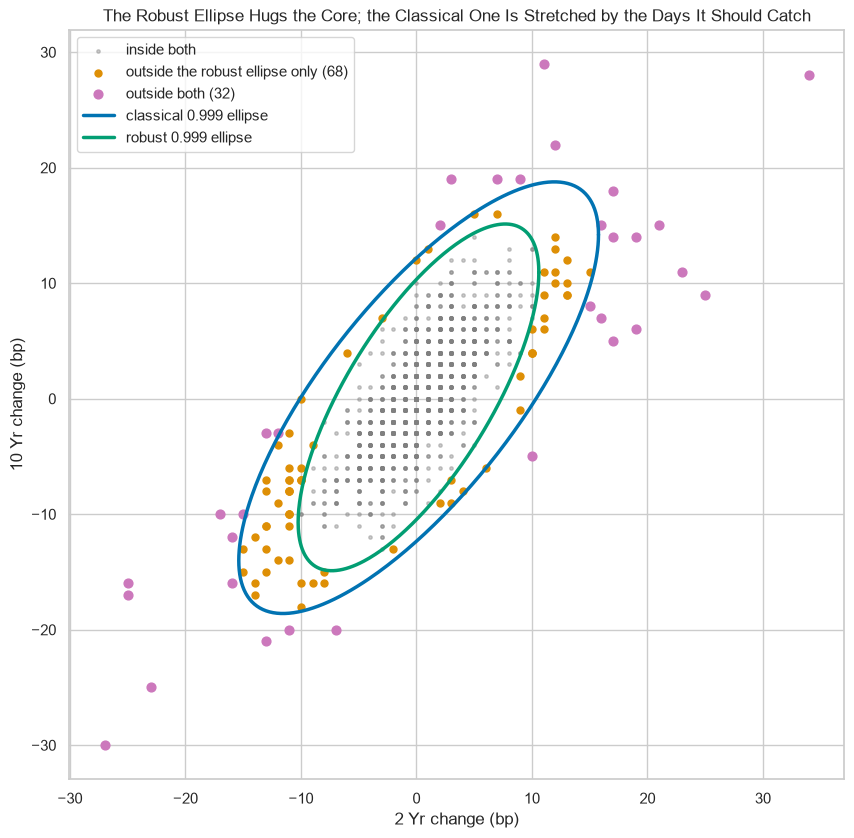

In [19]:
# both 0.999 ellipses on one cloud, each drawn through its covariance's Cholesky factor, the days outside coloured
fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(two.loc[~outside_robust, "2 Yr"], two.loc[~outside_robust, "10 Yr"], s=6, color="gray", alpha=0.4, label="inside both")
only_robust = outside_robust & ~outside_classical
ax.scatter(two.loc[only_robust, "2 Yr"], two.loc[only_robust, "10 Yr"], s=25, color="C1", label=f"outside the robust ellipse only ({only_robust.sum()})")
ax.scatter(two.loc[outside_classical, "2 Yr"], two.loc[outside_classical, "10 Yr"], s=40, color="C4", label=f"outside both ({outside_classical.sum()})")
for fit, fit_name, colour in [(classical2, "classical", "C0"), (robust2, "robust", "C2")]:
    ring = fit.location_ + np.sqrt(cut_two) * circle @ np.linalg.cholesky(fit.covariance_).T
    ax.plot(ring[:, 0], ring[:, 1], color=colour, linewidth=2.5, label=f"{fit_name} 0.999 ellipse")
ax.set_aspect("equal")
ax.set(xlabel="2 Yr change (bp)", ylabel="10 Yr change (bp)", title="The Robust Ellipse Hugs the Core; the Classical One Is Stretched by the Days It Should Catch")
ax.legend(loc="upper left")
plt.show()

### Interpretation of the Two Ellipses

The robust ellipse keeps nearly the same tilt and draws in on every side.

Every day outside the classical ellipse is outside the robust one too.

The unusual days had stretched the classical yardstick: Day 6's masking, in two columns.

## Days Beyond the Cutoff

In [20]:
# the robust yardstick on four tenors: its core, and each tenor's sd (bp) from each covariance's diagonal (np.diag reads it)
robust = MinCovDet(random_state=SEED).fit(changes)
d2_robust = pd.Series(robust.mahalanobis(changes), index=changes.index).round(6)
print("Core:", robust.support_.sum(), "of", len(changes), "days")

# the days beyond the cutoff on each yardstick, and the robust ones year by year
flag_classical, flag_robust = d2_classical > cut_four, d2_robust > cut_four
print("Classical:", flag_classical.sum(), "| robust:", flag_robust.sum(), "| classical days among the robust:", (flag_classical & flag_robust).sum(), "| robust only:", (flag_robust & ~flag_classical).sum())
print("Robust days by year:", flag_robust.groupby(flag_robust.index.year).sum().to_dict())
pd.DataFrame({"classical sd": np.sqrt(np.diag(classical.covariance_)), "robust sd": np.sqrt(np.diag(robust.covariance_))}, index=TENORS).round(2)

Core: 1746 of 2000 days
Classical: 44 | robust: 122 | classical days among the robust: 44 | robust only: 78
Robust days by year: {2015: 5, 2016: 7, 2017: 2, 2018: 2, 2019: 12, 2020: 20, 2021: 11, 2022: 63}


,classical sd,robust sd
2 Yr,4.19,2.82
5 Yr,4.96,3.72
10 Yr,5.03,4.01
30 Yr,4.96,4.08


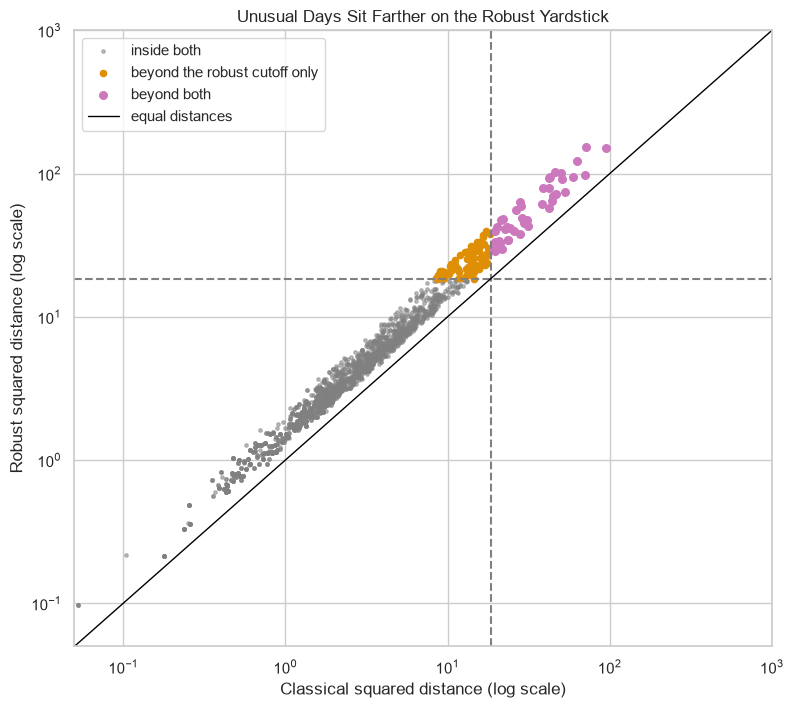

In [21]:
# each day's two squared distances, log on both axes, both cutoffs dashed
fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(d2_classical[~flag_robust], d2_robust[~flag_robust], s=6, color="gray", alpha=0.5, label="inside both")
ax.scatter(d2_classical[flag_robust & ~flag_classical], d2_robust[flag_robust & ~flag_classical], s=20, color="C1", label="beyond the robust cutoff only")
ax.scatter(d2_classical[flag_classical], d2_robust[flag_classical], s=30, color="C4", label="beyond both")
ax.axvline(cut_four, color="gray", linestyle="--")
ax.axhline(cut_four, color="gray", linestyle="--")
ax.plot([0.01, 1000], [0.01, 1000], color="black", linewidth=1, label="equal distances")
ax.set(xscale="log", yscale="log", xlim=(0.05, 1000), ylim=(0.05, 1000), xlabel="Classical squared distance (log scale)", ylabel="Robust squared distance (log scale)",
       title="Unusual Days Sit Farther on the Robust Yardstick")
ax.legend(loc="upper left")
plt.show()

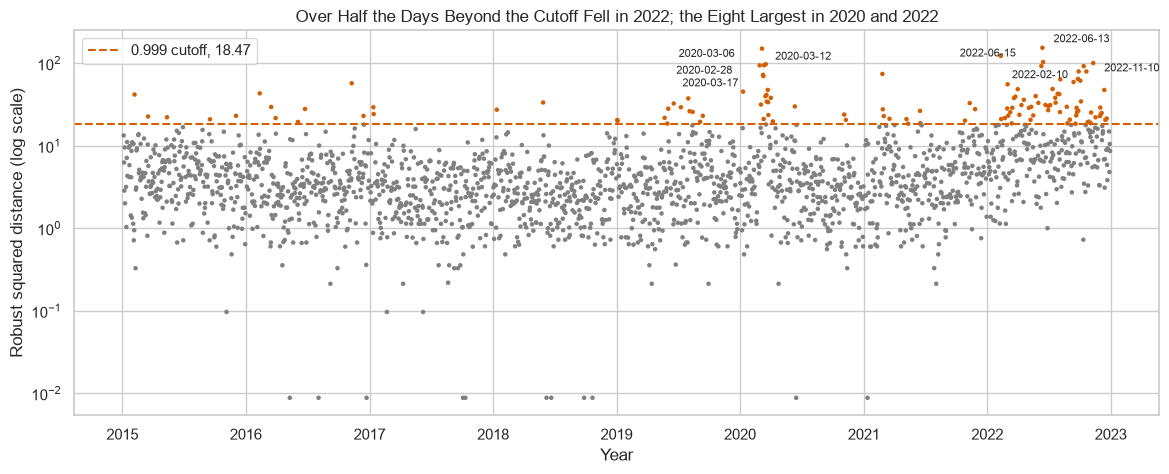

In [22]:
# every day's robust squared distance through time, log axis, the cutoff dashed and the eight largest dated
top = d2_robust.nlargest(8)
fig, ax = plt.subplots(figsize=(14, 5))
ax.scatter(d2_robust.index, d2_robust, s=5, color=np.where(flag_robust, "C3", "gray"))
ax.axhline(cut_four, color="C3", linestyle="--", label=f"0.999 cutoff, {cut_four:.2f}")
for rank, (day, value) in enumerate(top.items()):
    ax.annotate(str(day.date()), (day, value), xytext=(-60 if rank % 2 else 8, 4 - 10 * (rank % 3)), textcoords="offset points", fontsize=8)
ax.set_yscale("log")
ax.set(xlabel="Year", ylabel="Robust squared distance (log scale)", title="Over Half the Days Beyond the Cutoff Fell in 2022; the Eight Largest in 2020 and 2022")
ax.legend(loc="upper left")
plt.show()

## The Unusual Days, as History

In [23]:
# the eight days with the largest robust distance, and each tenor's change that day (bp)
changes.loc[top.index].round().astype(int).assign(squared_distance=top.round(1))

,2 Yr,5 Yr,10 Yr,30 Yr,squared_distance
date,,,,,
2022-06-13,34,31,28,22,154.0
2020-03-06,-10,-9,-18,-31,150.6
2022-02-10,25,14,9,5,122.6
2022-06-15,-25,-23,-16,-6,103.3
2022-11-10,-27,-32,-30,-28,100.6
2020-03-17,11,17,29,29,97.5
2020-03-12,0,0,6,19,94.7
2020-02-28,-25,-22,-17,-14,94.2


These are the days the four changes were the most unusual together, listed as history.

The file does not record why any day moved.

## Ordinary in Every Tenor

In [24]:
# Day 6's robust z for each tenor, and the robust-flagged days with every tenor within 3.5
tenor_z = (changes - changes.median()) / (1.4826 * (changes - changes.median()).abs().median())
ordinary_each = (tenor_z.round(6).abs() <= 3.5).all(axis=1)
print("Flagged days with every tenor within 3.5:", (flag_robust & ordinary_each).sum(), "of", flag_robust.sum())
print("2022-07-13:", changes.loc["2022-07-13"].round().astype(int).tolist(), "bp | robust squared distance:", d2_robust["2022-07-13"].round(2))

Flagged days with every tenor within 3.5: 51 of 122
2022-07-13: [10, 1, -5, -5] bp | robust squared distance: 48.75


2022-07-13 moved the 2 Yr up and the 10 Yr and 30 Yr down, each by an ordinary amount.

**A day can be ordinary tenor by tenor and unusual together, and the robust yardstick finds days the classical one hid.**

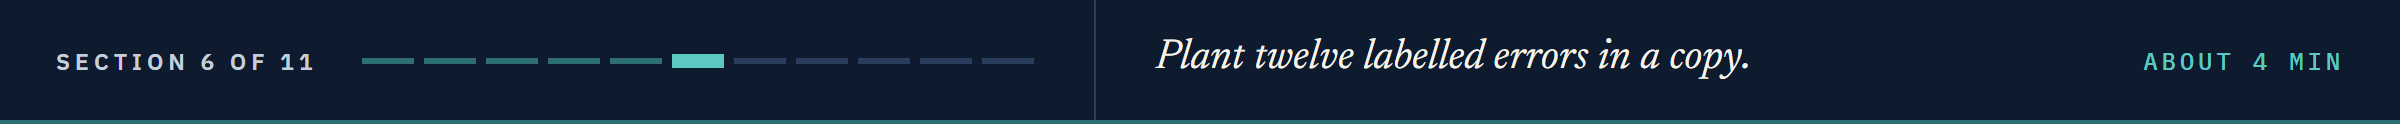

# Planting Field Errors

## Twelve Errors in a Copy

Day 6's planting, on the book: `rng.choice` picks 12 different bonds, four for each kind of error.

In [25]:
# one generator for the planting: 12 rows, four durations longer than the maturity, four coupons typed as decimals, four prices times ten
rng = np.random.default_rng(SEED)
rows = rng.choice(len(book), 12, replace=False)
too_long, as_decimal, times_ten = rows[:4], rows[4:8], rows[8:]

# a copy of the book with the three kinds of error
bonds = book.copy()
bonds.loc[too_long, "duration"] = (bonds.loc[too_long, "years_to_maturity"] * rng.uniform(1.3, 1.8, 4)).round(3)
bonds.loc[as_decimal, "coupon"] = bonds.loc[as_decimal, "coupon"] / 100
bonds.loc[times_ten, "price"] = bonds.loc[times_ten, "price"] * 10

# the labels: a bond is planted where any of the three fields differs from the file
FIELDS = ["coupon", "price", "duration"]
planted = (bonds[FIELDS] != book[FIELDS]).any(axis=1)
print("Planted bonds:", planted.sum())

Planted bonds: 12


In [26]:
# the 12 planted bonds, each field before and after
kind = pd.Series("ordinary", index=bonds.index, name="planted kind")
kind[too_long], kind[as_decimal], kind[times_ten] = "duration", "coupon", "price"
table = book.loc[rows, ["issuer", "cusip", "years_to_maturity", "coupon", "price", "duration"]].round(3)
table[["new_coupon", "new_price", "new_duration"]] = bonds.loc[rows, FIELDS].round(3).to_numpy()
table.assign(kind=kind[rows])

,issuer,cusip,years_to_maturity,coupon,price,duration,new_coupon,new_price,new_duration,kind
84,Halvering Foods,99004EAB3,26.689,7.625,88.366,10.218,7.625,88.366,43.287,duration
194,Zarizal Industrial,99129ZAB6,10.563,8.250,101.481,6.756,8.250,101.481,18.077,duration
147,Sylvazor Power,99095RAA6,10.229,3.500,89.614,8.291,3.500,89.614,15.565,duration
104,Lorvellix Energy,99144OAF3,10.995,5.750,104.801,8.157,5.750,104.801,15.543,duration
125,Pellwick Paper,99003DAG5,1.076,5.125,100.459,1.017,0.051,100.459,1.017,coupon
166,Tromithe Medical,99093PAB0,3.669,6.375,101.051,3.170,0.064,101.051,3.170,coupon
16,Clavolvey Bancorp,99141LAA3,6.089,6.375,98.831,4.840,0.064,98.831,4.840,coupon
83,Halvering Foods,99004EAA5,10.877,6.500,96.683,7.582,0.065,96.683,7.582,coupon
18,Calderby Retail,99009JAC5,23.726,9.250,95.248,9.019,9.250,952.480,9.019,price
136,Quorvane Energy,99001BAA4,7.291,4.875,98.882,6.000,4.875,988.820,6.000,price


Two Halvering Foods bonds carry one planted error each: the 26.69-year bond's duration 10.218 became 43.287, the other's coupon 6.500 became 0.065.

The copy is never written to disk.

## The Screen's Columns

In [27]:
# the five columns the screens read, OAS as its log
bonds["log_oas"] = np.log(bonds["oas"])
SCREEN = ["coupon", "price", "log_oas", "duration", "years_to_maturity"]
features = bonds[SCREEN]

# Day 6's robust z per column, (value - median) / (1.4826 x MAD), chosen before any label is read
median = features.median()
scaled = (features - median) / (1.4826 * (features - median).abs().median())

In [28]:
# a demonstration with the labels, which choose nothing: price's sd with and without the planted bonds, and its scaled MAD
print("Price sd with the planted bonds:", round(features["price"].std(), 2), "| without:", round(features.loc[~planted, "price"].std(), 2),
      "| scaled MAD:", round(1.4826 * (features["price"] - median["price"]).abs().median(), 2))

Price sd with the planted bonds: 125.5 | without: 7.54 | scaled MAD: 5.94


The four prices times ten stretch price's sd; the scaled MAD stays near the ordinary bonds' sd, the yardstick Day 6 chose.

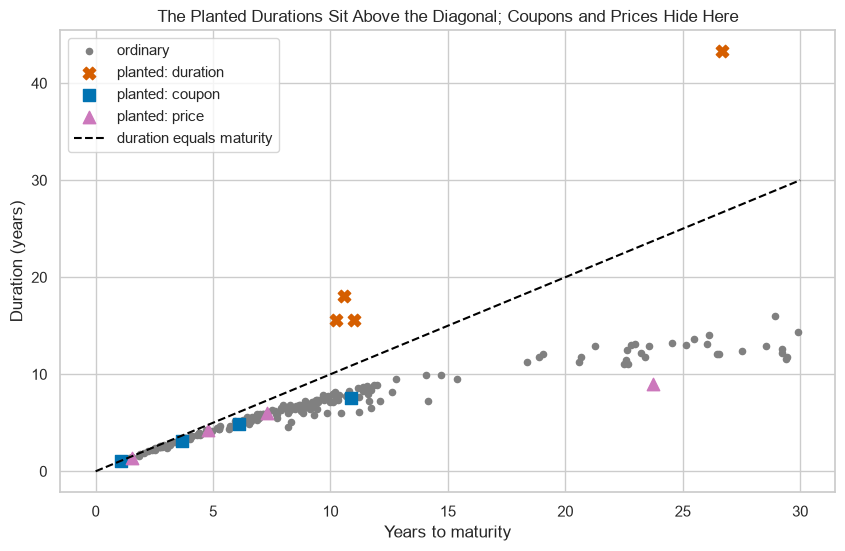

In [29]:
# duration against years to maturity in the copy, the diagonal where they are equal, planted bonds by kind
plt.figure(figsize=(10, 6))
for name, marker, colour in [("ordinary", "o", "gray"), ("duration", "X", "C3"), ("coupon", "s", "C0"), ("price", "^", "C4")]:
    part = bonds[kind == name]
    plt.scatter(part["years_to_maturity"], part["duration"], marker=marker, color=colour, s=20 if name == "ordinary" else 80, label=name if name == "ordinary" else f"planted: {name}")
plt.plot([0, 30], [0, 30], color="black", linestyle="--", label="duration equals maturity")
plt.xlabel("Years to maturity")
plt.ylabel("Duration (years)")
plt.title("The Planted Durations Sit Above the Diagonal; Coupons and Prices Hide Here")
plt.legend()
plt.show()

In [30]:
# the planted durations' robust z, one column at a time
scaled.loc[too_long, ["duration", "years_to_maturity"]].round(2).assign(issuer=bonds.loc[too_long, "issuer"])

,duration,years_to_maturity,issuer
84,12.20,3.73,Halvering Foods
194,3.88,0.46,Zarizal Industrial
147,3.06,0.39,Sylvazor Power
104,3.05,0.55,Lorvellix Energy


Each planted duration breaks the diagonal, yet three of the four are only modestly high on their own column.

## Day 6's Screen, Field by Field

Day 6's `screen_performance`, repeated as one cell, scores a screen's flags against the planted labels.

In [31]:
# one row of scores for a screen: its flags against the planted labels
def screen_performance(flags, planted):
    """One row: the flags, the planted bonds found, recall, precision and F1."""
    return pd.DataFrame({"Flags": [flags.sum()], "Planted Found": [(flags & planted).sum()],
                         "Recall": [recall_score(planted, flags)], "Precision": [precision_score(planted, flags)],
                         "F1": [f1_score(planted, flags)]})

# a bond is flagged where any column's |robust z| is above 3.5
field_flags = (scaled.round(6).abs() > 3.5).any(axis=1)
print("Planted bonds missed:", bonds.loc[planted & ~field_flags, "issuer"].tolist())
screen_performance(field_flags, planted).round(3)

Planted bonds missed: ['Lorvellix Energy', 'Sylvazor Power']


,Flags,Planted Found,Recall,Precision,F1
0,27,10,0.833,0.37,0.513


The screen finds the far values and misses two planted durations whose columns disagree only together.

**One field at a time misses a pair that disagrees.**

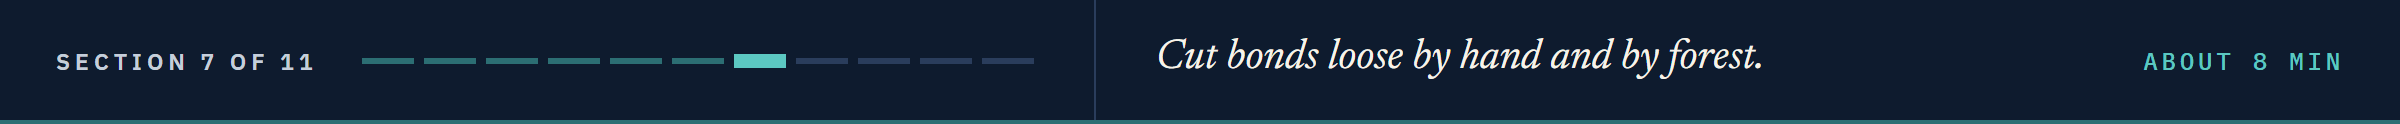

# Isolation Forest

## Cutting a Bond Loose

An **isolation tree** makes **random cuts**: it picks a column at random and a cut at random between that column's lowest and highest value among the rows left, then keeps the side the bond is on.
The number of cuts until the bond stands alone is its **path length**.
A forest of such trees is Course 5's Day 3 forest of randomized trees, grown to isolate rather than to fit.

In [32]:
# the random cuts one tree makes until the target row stands alone
def cuts_to_isolate(values, target, rng):
    """The random cuts one isolation tree makes until the target row stands alone, as (column, value) pairs."""
    remaining = values
    cuts = []
    while len(remaining) > 1:
        column = rng.integers(values.shape[1])
        cut = rng.uniform(remaining[:, column].min(), remaining[:, column].max())
        # keep the rows on the same side of the cut as the target
        remaining = remaining[(remaining[:, column] < cut) == (target[column] < cut)]
        cuts.append((column, cut))
    return cuts

In [33]:
# maturity and duration as a NumPy array, and three bonds found by CUSIP
pair = bonds[["years_to_maturity", "duration"]].to_numpy()
praxane, halvering, lorvellix = [bonds.index[bonds["cusip"] == cusip][0] for cusip in ["99015PAD1", "99004EAB3", "99144OAF3"]]
bonds.loc[[praxane, halvering, lorvellix], ["issuer", "cusip", "rating", "years_to_maturity", "duration"]].round(2)

,issuer,cusip,rating,years_to_maturity,duration
130,Praxane Paper,99015PAD1,BB-,8.27,6.32
84,Halvering Foods,99004EAB3,B+,26.69,43.29
104,Lorvellix Energy,99144OAF3,BBB+,11.00,15.54


In [34]:
# Praxane Paper's path length in 1,000 trees, on the first of three spawned streams (Day 1's spawn and standard error)
streams = np.random.default_rng(SEED).spawn(3)
paths = {"Praxane Paper": np.array([len(cuts_to_isolate(pair, pair[praxane], streams[0])) for _ in range(1000)])}
print("Praxane Paper: average path", round(paths["Praxane Paper"].mean(), 2), "cuts | standard error", round(paths["Praxane Paper"].std(ddof=1) / np.sqrt(1000), 3))

Praxane Paper: average path 14.43 cuts | standard error 0.103


An ordinary bond in the middle of the cloud takes about 14 cuts to stand alone.

**Predict 4**

Halvering Foods' 26.7-year bond (`99004EAB3`) now carries a duration of 43.287 years.

Q. What is its average path length over 1,000 trees? Write down a number.

## The Average Path

In [35]:
# Halvering Foods' and Lorvellix Energy's path lengths on the other two streams
paths["Halvering Foods"] = np.array([len(cuts_to_isolate(pair, pair[halvering], streams[1])) for _ in range(1000)])
paths["Lorvellix Energy"] = np.array([len(cuts_to_isolate(pair, pair[lorvellix], streams[2])) for _ in range(1000)])
for name in ["Halvering Foods", "Lorvellix Energy"]:
    print(f"{name}: average path", round(paths[name].mean(), 3), "cuts | standard error", round(paths[name].std(ddof=1) / np.sqrt(1000), 3))

Halvering Foods: average path 2.585 cuts | standard error 0.052
Lorvellix Energy: average path 6.745 cuts | standard error 0.061


In [36]:
# one tree on a scatter: each cut a numbered line across the box of rows still left
def draw_tree(ax, row, rng):
    """Draw one isolation tree's cuts closing in on one bond, and return the number of cuts."""
    box = [pair[:, 0].min(), pair[:, 0].max(), pair[:, 1].min(), pair[:, 1].max()]
    cuts = cuts_to_isolate(pair, pair[row], rng)
    for number, (column, value) in enumerate(cuts, start=1):
        if column == 0:
            ax.plot([value, value], box[2:], color="C0")
            ax.text(value, box[2] + (box[3] - box[2]) * 0.12 * number, str(number), color="C0", ha="center", backgroundcolor="white")
        else:
            ax.plot(box[:2], [value, value], color="C0")
            ax.text(box[0] + (box[1] - box[0]) * 0.12 * number, value, str(number), color="C0", va="center", backgroundcolor="white")
        # the box shrinks to the bond's side of the cut: its low edge moves up, or its high edge moves down
        box[2 * column + (0 if pair[row, column] > value else 1)] = value
    ax.scatter(pair[:, 0], pair[:, 1], s=8, color="gray", alpha=0.5)
    ax.scatter(pair[row, 0], pair[row, 1], s=150, color="C3", zorder=3)
    return len(cuts)

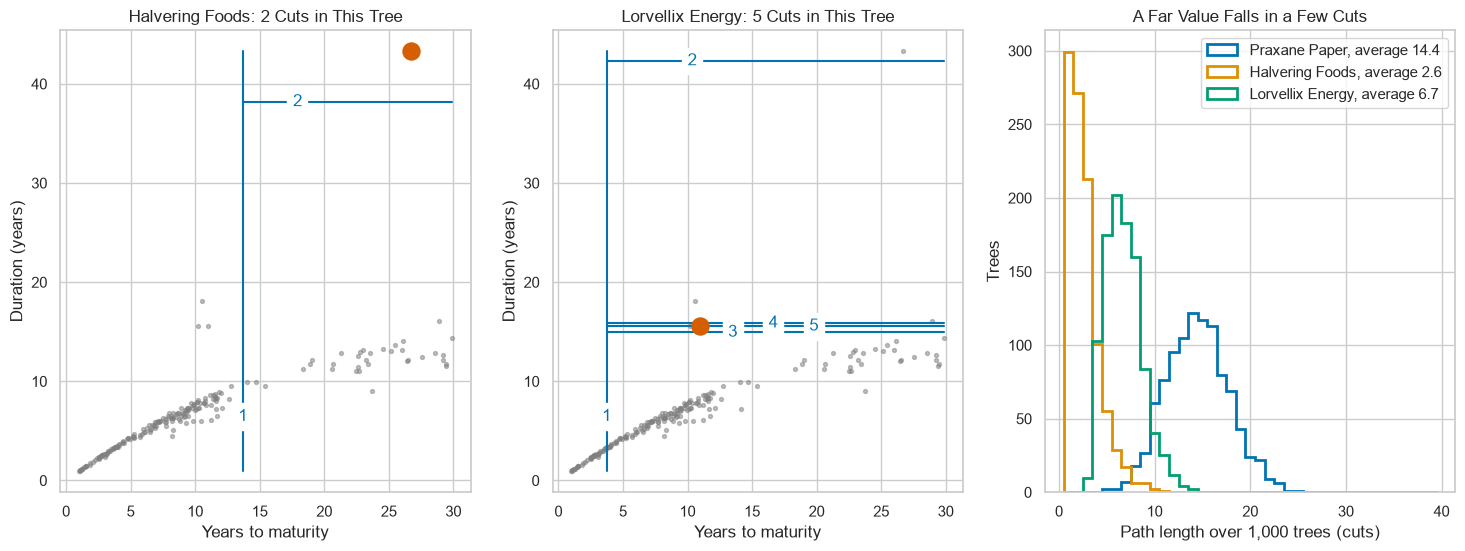

In [37]:
# one tree each for the two planted bonds from a fresh generator, and the 1,000-tree path lengths beside
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, name, row in [(axes[0], "Halvering Foods", halvering), (axes[1], "Lorvellix Energy", lorvellix)]:
    number_of_cuts = draw_tree(ax, row, rng)
    ax.set(xlabel="Years to maturity", ylabel="Duration (years)", title=f"{name}: {number_of_cuts} Cuts in This Tree")
for name, lengths in paths.items():
    axes[2].hist(lengths, bins=np.arange(0.5, 40.5, 1), histtype="step", linewidth=2, label=f"{name}, average {lengths.mean():.1f}")
axes[2].set(xlabel="Path length over 1,000 trees (cuts)", ylabel="Trees", title="A Far Value Falls in a Few Cuts")
axes[2].legend()
plt.show()

In Halvering Foods' tree the first cut, on maturity, leaves it with the long bonds, and the second, on duration, frees it.

Lorvellix Energy sits beside another planted duration (Sylvazor Power's 15.565 against its 15.543), so its tree needs three cuts close around it; over 1,000 trees it still needs fewer than half Praxane Paper's cuts.

## Scikit-learn's Forest

`IsolationForest` grows 100 trees, each on a sample of up to 256 bonds (here all 200), and turns a bond's average path into a **score** from 0 to 1, higher for a shorter path.
A score above 0.5 means a bond is isolated in fewer cuts than the average path in a random tree of 200 rows.
A tree needs no scaling (Course 4's Day 9), so the forest reads the five columns as they are.

In [38]:
# the average path in a random tree of n rows: 2 x (ln(n - 1) + 0.5772) - 2 x (n - 1) / n, with Euler's constant 0.5772
n = len(bonds)
print("Average path in a random tree of 200 rows:", round(2 * (np.log(n - 1) + 0.5772156649) - 2 * (n - 1) / n, 2))

# the forest on the five columns; .predict() gives -1 for a flag, and the score is minus .score_samples()
forest = IsolationForest(random_state=SEED, n_jobs=1).fit(features)
forest_score = pd.Series(-forest.score_samples(features), index=bonds.index)
forest_flags = pd.Series(forest.predict(features) == -1, index=bonds.index)
print("Threshold (minus offset_):", -forest.offset_, "| Lorvellix Energy's score:", round(forest_score[lorvellix], 3), "| its rank:", int(forest_score.rank(ascending=False)[lorvellix]))
screen_performance(forest_flags, planted).round(3)

Average path in a random tree of 200 rows: 9.75
Threshold (minus offset_): 0.5 | Lorvellix Energy's score: 0.465 | its rank: 39


,Flags,Planted Found,Recall,Precision,F1
0,22,11,0.917,0.5,0.647


scikit-learn stops each tree at depth 8 (log2 of 200, rounded up) and adds the average path expected for the rows left in a leaf, so its path lengths are close to, not equal to, the hand counts of `cuts_to_isolate`.

The forest finds 11 planted bonds among 22 flags; Lorvellix Energy's score is under 0.5.

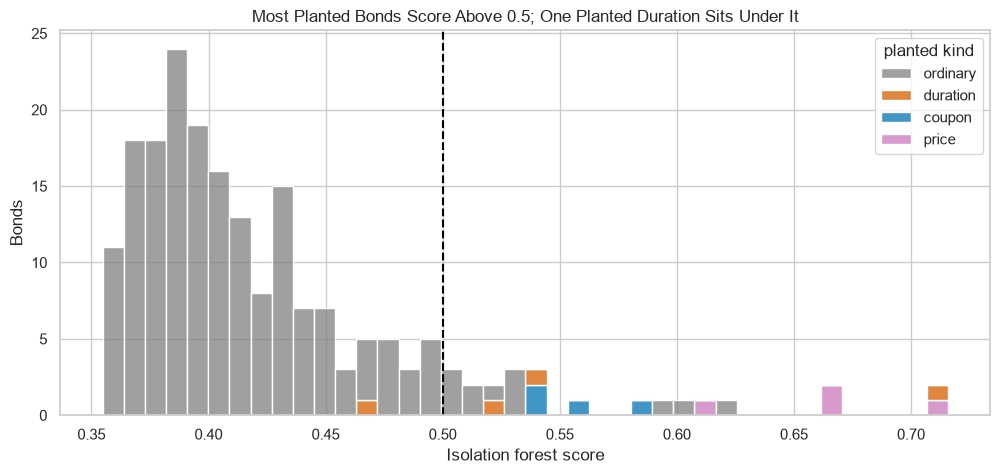

In [39]:
# the forest's scores, the planted bonds stacked by kind, the 0.5 threshold dashed
plt.figure(figsize=(12, 5))
sns.histplot(x=forest_score, hue=kind, hue_order=["ordinary", "duration", "coupon", "price"], multiple="stack", bins=40,
             palette=["gray", "C3", "C0", "C4"])
plt.axvline(0.5, color="black", linestyle="--")
plt.xlabel("Isolation forest score")
plt.ylabel("Bonds")
plt.title("Most Planted Bonds Score Above 0.5; One Planted Duration Sits Under It")
plt.show()

## The Settings

In [40]:
# each setting moved alone, the rest at their defaults: the flags and the recall
results = []
for setting, values in [("n_estimators", [25, 50, 100, 200, 400]), ("max_samples", [16, 32, 64, 128, 200]), ("max_features", [0.4, 0.6, 0.8, 1.0])]:
    for value in values:
        # **{setting: value} hands the forest one setting by its name
        flags = pd.Series(IsolationForest(**{setting: value}, random_state=SEED, n_jobs=1).fit(features).predict(features) == -1, index=bonds.index)
        results.append(screen_performance(flags, planted).assign(setting=setting, value=str(value)))
sweep = pd.concat(results, ignore_index=True)
sweep[["setting", "value", "Flags", "Recall", "Precision"]].round(3)

,setting,value,Flags,Recall,Precision
0,n_estimators,25,30,0.917,0.367
1,n_estimators,50,25,0.917,0.440
2,n_estimators,100,22,0.917,0.500
3,n_estimators,200,25,0.917,0.440
4,n_estimators,400,27,0.917,0.407
5,max_samples,16,75,0.917,0.147
6,max_samples,32,61,0.917,0.180
7,max_samples,64,42,1.000,0.286
8,max_samples,128,29,0.917,0.379
9,max_samples,200,22,0.917,0.500


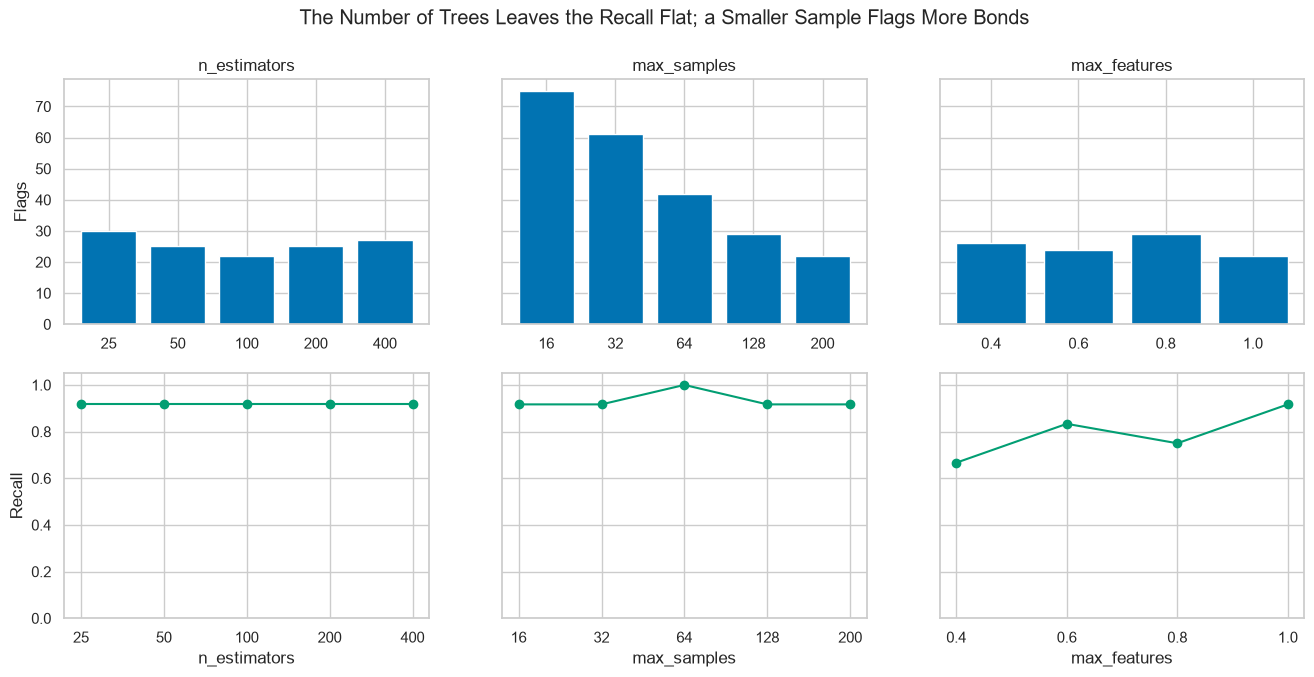

In [41]:
# the flags and the recall against each setting, one column of panels a setting
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharey="row")
for column, setting in enumerate(["n_estimators", "max_samples", "max_features"]):
    part = sweep[sweep["setting"] == setting]
    axes[0, column].bar(part["value"], part["Flags"], color="C0")
    axes[1, column].plot(part["value"], part["Recall"], marker="o", color="C2")
    axes[1, column].set(xlabel=setting, ylim=(0, 1.05))
    axes[0, column].set(title=setting)
axes[0, 0].set_ylabel("Flags")
axes[1, 0].set_ylabel("Recall")
fig.suptitle("The Number of Trees Leaves the Recall Flat; a Smaller Sample Flags More Bonds")
plt.show()

`n_estimators`, the number of trees, moves the flags between 22 and 30 and leaves the recall at 0.917.

`max_samples`, the bonds each tree sees, moves the flags most: a tree on 16 bonds isolates almost anything quickly.

`max_features`, the share of columns each tree reads, moves the recall between 0.667 and 0.917.

**The defaults, written down before the labels, stay.**

> STORY: Fei Tony Liu, Kai Ming Ting and Zhi-Hua Zhou introduced the isolation forest in 2008.
> Their introduction: "In other words, anomalies are 'few and different', which make them more susceptible to isolation than normal points."
> They averaged over 1,000 trees, as this notebook's hand trees did: "Using 1000 trees, the average path lengths of x_o and x_i converge to 4.02 and 12.82 respectively."
> And on the sample size: "A small sample size produces better iTrees because the swamping and masking effects are reduced."
> Source: F. T. Liu, K. M. Ting and Z.-H. Zhou, "Isolation Forest", Eighth IEEE International Conference on Data Mining (ICDM), 2008, sections 1 and 2, https://www.lamda.nju.edu.cn/publication/icdm08b.pdf

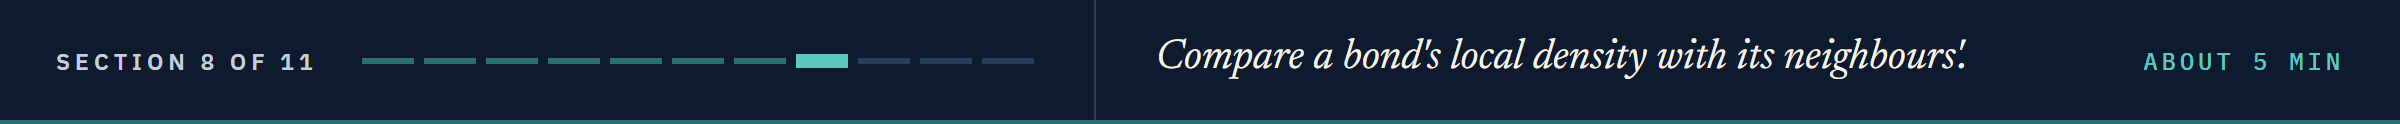

# Local Outlier Factor

## A Bond and Its Neighbours

A bond's **k-distance** is its distance to its k-th nearest neighbour, found with Course 5's Day 13 `NearestNeighbors` and `.kneighbors()`.
A bond in a crowd has a short k-distance; a bond alone has a long one.
This demonstration reads two columns in robust z, maturity and duration, with k = 20.

In [42]:
# each bond's 20 nearest neighbours on maturity and duration in robust z (the first neighbour found is the bond itself)
two_columns = scaled[["years_to_maturity", "duration"]]
distances, neighbours = NearestNeighbors(n_neighbors=21, n_jobs=1).fit(two_columns).kneighbors(two_columns)
k_distance = distances[:, 20]
print("On two columns, Lorvellix Energy's k-distance:", round(k_distance[lorvellix], 2), "| its 20 neighbours' median:", round(np.median(k_distance[neighbours[lorvellix, 1:]]), 2))

On two columns, Lorvellix Energy's k-distance: 2.39 | its 20 neighbours' median: 0.83


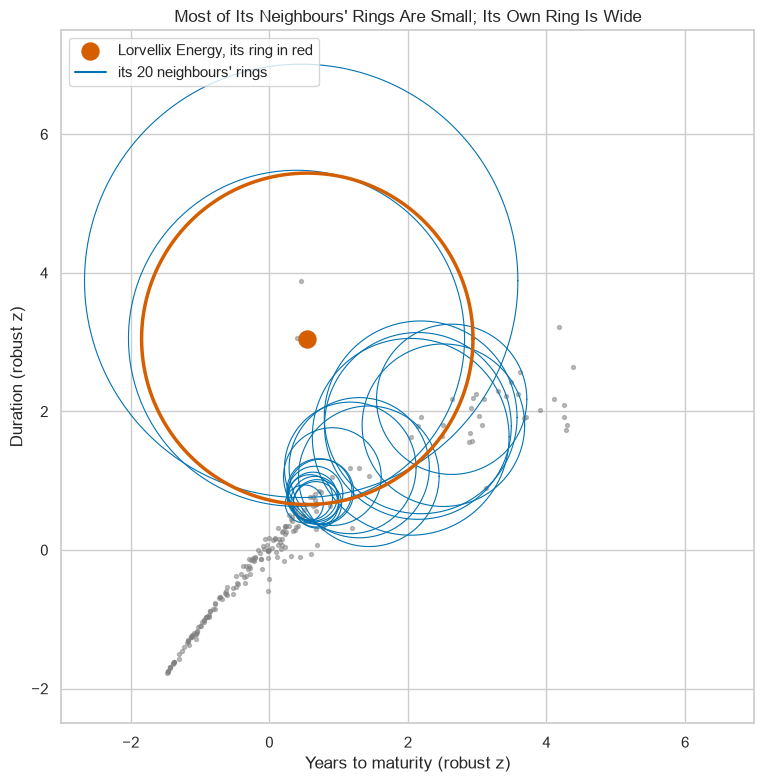

In [43]:
# Lorvellix Energy and its 20 neighbours, each ringed at its own k-distance (equal axes, so a ring is a circle)
fig, ax = plt.subplots(figsize=(9, 9))
ax.scatter(two_columns["years_to_maturity"], two_columns["duration"], s=8, color="gray", alpha=0.5)
for row in list(neighbours[lorvellix, 1:]) + [lorvellix]:
    ring = two_columns.iloc[row].to_numpy() + k_distance[row] * circle
    ax.plot(ring[:, 0], ring[:, 1], color="C3" if row == lorvellix else "C0", linewidth=2.5 if row == lorvellix else 0.8)
ax.scatter(two_columns.iloc[lorvellix, 0], two_columns.iloc[lorvellix, 1], s=150, color="C3", zorder=3, label="Lorvellix Energy, its ring in red")
ax.plot([], [], color="C0", label="its 20 neighbours' rings")  # an empty line, only for the legend
ax.set_aspect("equal")
ax.set(xlim=(-3, 7), ylim=(-2.5, 7.5), xlabel="Years to maturity (robust z)", ylabel="Duration (robust z)", title="Most of Its Neighbours' Rings Are Small; Its Own Ring Is Wide")
ax.legend(loc="upper left")
plt.show()

The picture uses maturity and duration only; the screen below runs on all five columns.

On these two columns Lorvellix Energy's ring is about three times its neighbours': they sit in a crowd and it does not.

The two widest neighbouring rings belong to the other planted durations near it, Sylvazor Power's and Zarizal Industrial's.

The **local outlier factor (LOF)** compares a bond's local density with its neighbours': close to 1 inside a crowd, well above 1 for a bond in a sparser spot than its neighbours.

## LOF on the Five Columns

In [44]:
# LOF at 20 neighbours on the five columns in robust z; .fit_predict() gives -1 for a flag, the factor is minus negative_outlier_factor_
lof = LocalOutlierFactor(n_neighbors=20, n_jobs=1)
lof_flags = pd.Series(lof.fit_predict(scaled) == -1, index=bonds.index)
lof_score = pd.Series(-lof.negative_outlier_factor_, index=bonds.index)
print("Threshold:", -lof.offset_, "| Lorvellix Energy's factor:", round(lof_score[lorvellix], 2), "| the prices times ten:", lof_score[times_ten].round(1).tolist())
screen_performance(lof_flags, planted).round(3)

Threshold: 1.5 | Lorvellix Energy's factor: 1.69 | the prices times ten: [62.5, 64.6, 67.1, 64.9]


,Flags,Planted Found,Recall,Precision,F1
0,25,12,1.0,0.48,0.649


In [45]:
# the ordinary bonds LOF flags, by their fields
bonds.loc[lof_flags & ~planted, ["issuer", "rating", "coupon", "price", "oas"]].assign(factor=lof_score.round(2))

,issuer,rating,coupon,price,oas,factor
17,Calderby Retail,B,9.500,62.045,1446,2.98
40,Dralane Networks,AAA,5.875,110.206,19,1.60
65,Feskovar Devices,CCC+,10.750,87.116,1551,1.97
66,Feskovar Devices,CCC+,8.875,87.473,614,1.78
72,Galvellix Paper,B-,9.250,87.457,679,1.62
108,Mulvebran Logistics,BB,3.875,81.455,189,1.52
117,Nevulex Health,BBB-,3.875,73.873,153,1.63
122,Plevundra Finance,AA,3.250,97.995,22,1.55
123,Plevundra Finance,AA,7.250,119.131,38,1.58
131,Praxiskan Finance,CCC+,11.000,100.010,707,1.54


LOF finds every planted bond, Lorvellix Energy among them at a factor of 1.69, and flags 13 ordinary bonds beside them.

The ordinary flags sit at the edges of the book's fields, Feskovar Devices' 1,551 bp the widest spread among them: records to check.

## Your Turn: Choose the Neighbourhood

In [46]:
# every bond's LOF on a log axis at k neighbours, the planted bonds as crosses, the 1.5 threshold dashed
def draw_lof(k=20):
    model = LocalOutlierFactor(n_neighbors=k, n_jobs=1)
    flags = model.fit_predict(scaled) == -1
    factor = -model.negative_outlier_factor_
    plt.figure(figsize=(14, 5))
    plt.scatter(np.arange(len(bonds))[~planted], factor[~planted], s=15, color="gray", label="ordinary")
    plt.scatter(np.arange(len(bonds))[planted], factor[planted], s=80, marker="X", color="C3", label="planted")
    plt.axhline(1.5, color="black", linestyle="--")
    plt.yscale("log")
    plt.xlabel("Bond, in the book's order")
    plt.ylabel("Local outlier factor (log scale)")
    plt.title(f"k = {k}: {flags.sum()} Flags, {(flags & planted).sum()} of 12 Planted Found")
    plt.legend(loc="upper left")
    plt.show()

In [47]:
# your turn: move k and watch the flags
interact(draw_lof, k=(5, 50, 5));

interactive(children=(IntSlider(value=20, description='k', max=50, min=5, step=5), Output()), _dom_classes=('w…

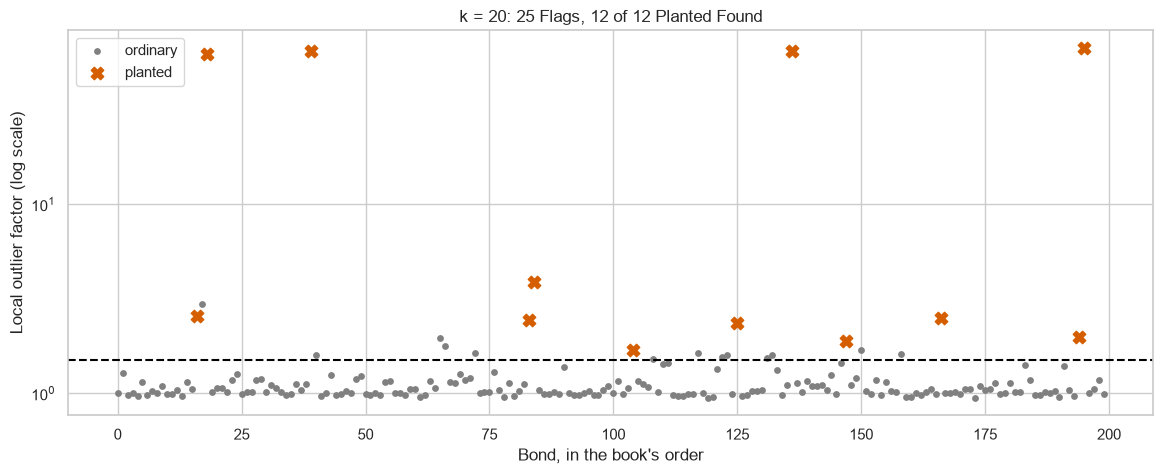

In [48]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_lof(k=20)

From 5 to 30 neighbours LOF finds all 12; from 35 one slips under the line.

**k = 20 stays, the library's default, set before the labels.**

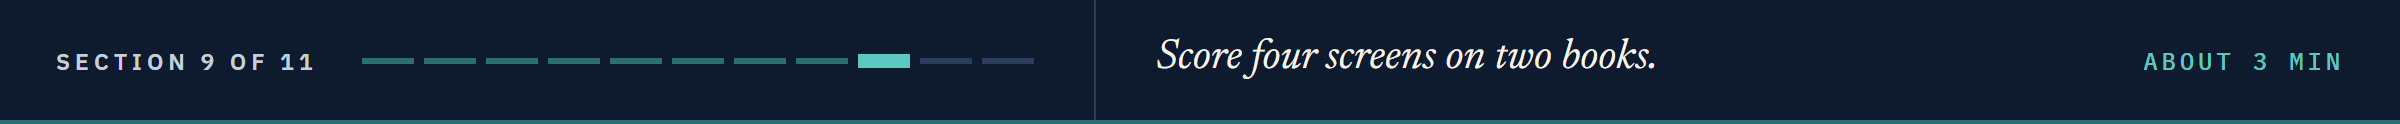

# Four Screens Side by Side

## The Robust Mahalanobis Screen on the Book

In [49]:
# MinCovDet on the five columns, the 0.999 cutoff for five, and the bonds beyond it
cut_five = stats.chi2.ppf(0.999, 5)
book_robust = MinCovDet(random_state=SEED).fit(features)
mahalanobis_flags = pd.Series(book_robust.mahalanobis(features), index=bonds.index).round(6) > cut_five
print("Cutoff:", round(cut_five, 2), "| core:", book_robust.support_.sum(), "of", len(bonds), "bonds")
screen_performance(mahalanobis_flags, planted).round(3)

Cutoff: 20.52 | core: 124 of 200 bonds


,Flags,Planted Found,Recall,Precision,F1
0,68,12,1.0,0.176,0.3


The robust distance finds every planted bond and flags 56 ordinary ones: the book is no tilted oval, so a core of 124 bonds leaves many outside.

## One Table

In [50]:
# the four screens, one row each
screens = {"field by field": field_flags, "robust Mahalanobis": mahalanobis_flags, "isolation forest": forest_flags, "LOF": lof_flags}
scores = pd.concat([screen_performance(flags, planted) for flags in screens.values()], ignore_index=True)
scores.index = list(screens)
scores.round(3)

,Flags,Planted Found,Recall,Precision,F1
field by field,27,10,0.833,0.370,0.513
robust Mahalanobis,68,12,1.000,0.176,0.300
isolation forest,22,11,0.917,0.500,0.647
LOF,25,12,1.000,0.480,0.649


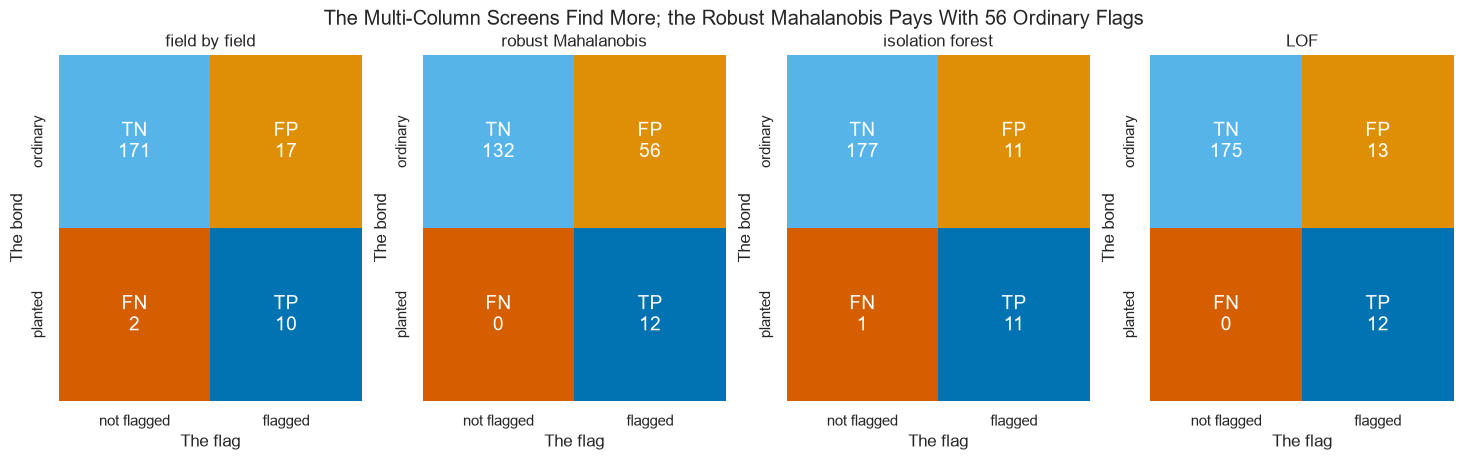

In [51]:
# draw a confusion matrix: each cell in its own colour, with its name and its count
def draw_confusion(flags, ax, title):
    tn, fp, fn, tp = confusion_matrix(planted, flags).ravel()
    labels = [[f"TN\n{tn}", f"FP\n{fp}"], [f"FN\n{fn}", f"TP\n{tp}"]]
    sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["not flagged", "flagged"], yticklabels=["ordinary", "planted"])
    ax.set(xlabel="The flag", ylabel="The bond", title=title)

# the four screens' confusion matrices
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (name, flags) in zip(axes, screens.items()):
    draw_confusion(flags, ax, name)
fig.suptitle("The Multi-Column Screens Find More; the Robust Mahalanobis Pays With 56 Ordinary Flags")
plt.show()

### Interpretation of the Four Screens

The isolation forest and LOF each find nearly every planted bond at about half precision; the field-by-field screen misses two.

## The Untouched Book

In [52]:
# the untouched book's five columns, and its own robust z
clean = book.assign(log_oas=np.log(book["oas"]))[SCREEN]
clean_scaled = (clean - clean.median()) / (1.4826 * (clean - clean.median()).abs().median())

# the four screens on a book with nothing planted
untouched = pd.Series({"field by field": (clean_scaled.round(6).abs() > 3.5).any(axis=1).sum(),
                       "robust Mahalanobis": (MinCovDet(random_state=SEED).fit(clean).mahalanobis(clean).round(6) > cut_five).sum(),
                       "isolation forest": (IsolationForest(random_state=SEED, n_jobs=1).fit(clean).predict(clean) == -1).sum(),
                       "LOF": (LocalOutlierFactor(n_neighbors=20, n_jobs=1).fit_predict(clean_scaled) == -1).sum()})
untouched

field by field        17
robust Mahalanobis    54
isolation forest      41
LOF                   13
dtype: int64

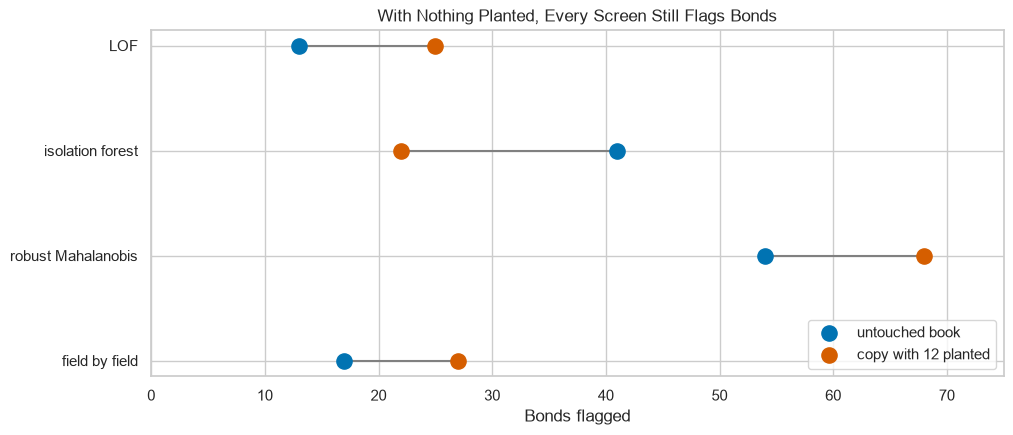

In [53]:
# each screen's flags on the copy and on the untouched book, joined by a line
fig, ax = plt.subplots(figsize=(11, 4.5))
for position, name in enumerate(screens):
    ax.plot([untouched[name], scores.loc[name, "Flags"]], [position, position], color="gray", zorder=1)
ax.scatter(untouched, range(4), s=120, color="C0", label="untouched book", zorder=2)
ax.scatter(scores["Flags"], range(4), s=120, color="C3", label="copy with 12 planted", zorder=2)
ax.set_yticks(range(4), list(screens))
ax.set(xlim=(0, 75), xlabel="Bonds flagged", title="With Nothing Planted, Every Screen Still Flags Bonds")
ax.legend(loc="lower right")
plt.show()

On a book with nothing planted the robust Mahalanobis screen flags 54 bonds and the forest 41; LOF flags 13.

The forest flags fewer on the copy than on the untouched book: its 0.5 threshold is fixed, and the planted bonds move every other bond's score.

**What a screen flags on a clean book is its running cost.**

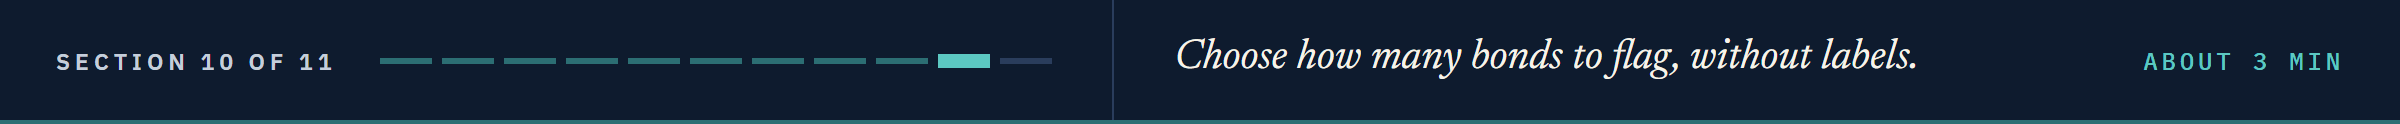

# Setting Contamination

`contamination` is the share of bonds a screen flags.
Set to a number, it flags that share of the highest scores, and 'auto' keeps the thresholds above.
It moves the line, never the ranking.

**Predict 5**

With 'auto', the forest found 11 of the 12 planted bonds among 22 flags.

Q. Set `contamination` to 12 / 200 = 0.06, the planted share: how many planted bonds does it find? Write down a number.

## Contamination From the Labels

In [54]:
# a demonstration with the labels, never a method: contamination copied from the planted share
share = planted.mean()
from_labels = {"forest": pd.Series(IsolationForest(contamination=share, random_state=SEED, n_jobs=1).fit(features).predict(features) == -1, index=bonds.index),
               "LOF": pd.Series(LocalOutlierFactor(n_neighbors=20, contamination=share, n_jobs=1).fit_predict(scaled) == -1, index=bonds.index)}
print("Contamination:", share)
labels_scores = pd.concat([screen_performance(flags, planted) for flags in from_labels.values()], ignore_index=True)
labels_scores.index = list(from_labels)
labels_scores.round(3)

Contamination: 0.06


,Flags,Planted Found,Recall,Precision,F1
forest,12,9,0.750,0.750,0.750
LOF,12,10,0.833,0.833,0.833


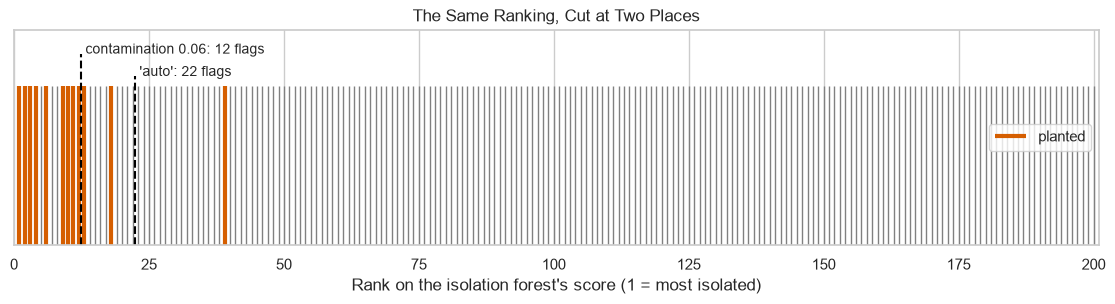

In [55]:
# every bond's rank on the forest's score as a barcode, planted in red, lines at 12 flags and at 'auto' (22)
rank = forest_score.rank(ascending=False)
fig, ax = plt.subplots(figsize=(14, 2.8))
ax.vlines(rank[~planted], 0, 1, color="gray", linewidth=1)
ax.vlines(rank[planted], 0, 1, color="C3", linewidth=3, label="planted")
for line, text, height in [(12.5, " contamination 0.06: 12 flags", 1.2), (22.5, " 'auto': 22 flags", 1.06)]:
    ax.vlines(line, 0, height, color="black", linestyle="--")
    ax.text(line, height, text, ha="left", fontsize=10)
ax.set(xlim=(0, 201), ylim=(0, 1.35), yticks=[], xlabel="Rank on the isolation forest's score (1 = most isolated)", title="The Same Ranking, Cut at Two Places")
ax.legend(loc="center right")
plt.show()

The count was copied from the answer, and a real book carries no labels, so no desk can repeat it.

The cut at 12 leaves three planted bonds outside it, two of them inside 'auto's 22.

## A Count the Desk Can Defend

A desk can check 10 bonds a day, so `contamination` is 10 / 200 = 0.05: the course's choice for this exercise, written down before any label is read.

In [56]:
# contamination from the cost of checking: 10 bonds of 200
budget = {"forest": pd.Series(IsolationForest(contamination=0.05, random_state=SEED, n_jobs=1).fit(features).predict(features) == -1, index=bonds.index),
          "LOF": pd.Series(LocalOutlierFactor(n_neighbors=20, contamination=0.05, n_jobs=1).fit_predict(scaled) == -1, index=bonds.index)}
budget_scores = pd.concat([screen_performance(flags, planted) for flags in budget.values()], ignore_index=True)
budget_scores.index = list(budget)
budget_scores.round(3)

,Flags,Planted Found,Recall,Precision,F1
forest,10,7,0.583,0.7,0.636
LOF,10,9,0.750,0.9,0.818


**A threshold or a contamination comes from a published rule, the cost of checking, or data without labels, never from the labels.**

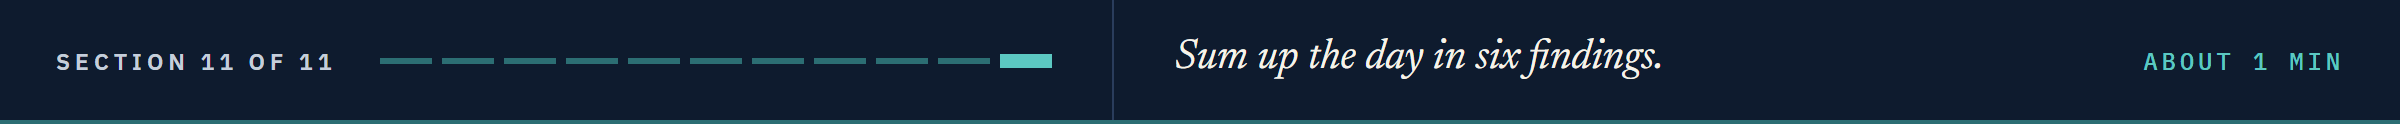

# Insights and Conclusion

2022-07-13 and 2016-03-01 tie in bp and differ 7.0 times in squared Mahalanobis distance.

In four tenors 44 days passed the classical 0.999 cutoff and 122 the robust one, where about 2 normal days would; 51 of the 122 were ordinary tenor by tenor.

On the book the field-by-field screen missed two planted durations; the forest found 11 of 12 and LOF 12 of 12, each at about half precision.

The robust Mahalanobis screen found 12 of 12 at a precision of 0.176 and flagged 54 bonds on the untouched book.

`contamination` copied from the labels found fewer than 'auto' and is no method.

A screen needs no rule written in advance for each kind of error; where a field check exists, it is the first check.

**Several columns at once, a yardstick the unusual rows did not build, and a threshold set before the labels.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Measure a squared Mahalanobis distance with a covariance matrix and its inverse, and set a chi-squared cutoff for it.
* Fit a classical and a robust covariance with `EmpiricalCovariance` and `MinCovDet`, and list unusual days as history.
* Plant field errors in a copy of a book and keep the labels for scoring only.
* Isolate a row with random cuts, and read an isolation forest's score and settings.
* Read a local outlier factor from a row's neighbours.
* Score a screen on planted labels and on an untouched book, and set `contamination` without the labels.

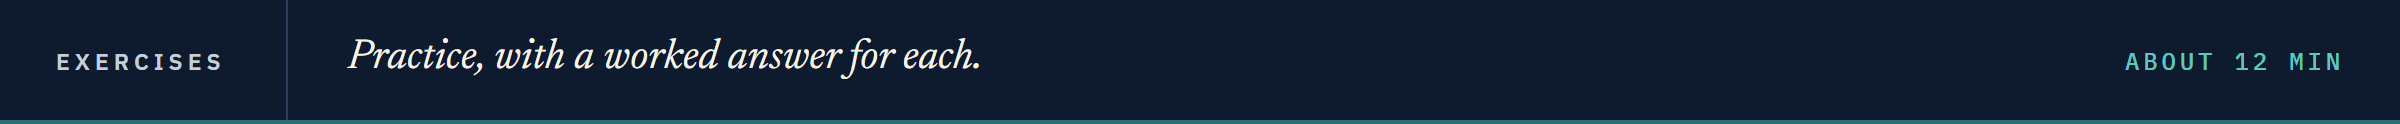

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [57]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**A Stricter Cutoff**

Q. Count the curve days whose robust squared distance in four tenors, `d2_robust`, is beyond the chi-squared 0.9999 cutoff, and store the count in `ex1_days`.

In [58]:
# your code here
ex1_days = ...

In [59]:
check("Exercise 1 the robust days beyond the 0.9999 cutoff", ex1_days, 83)

Exercise 1 the robust days beyond the 0.9999 cutoff: not attempted yet


### Exercise 2

**Precision at the Desk's Budget**

Q. Write `precision_at_k(scores, planted, k)`, the share of the k highest scores that are planted, and store the robust Mahalanobis screen's precision at k = 10 on the book in `ex2_precision`.

In [60]:
# your code here
ex2_precision = ...

In [61]:
check("Exercise 2 the robust Mahalanobis precision at 10", ex2_precision, 0.6)

Exercise 2 the robust Mahalanobis precision at 10: not attempted yet


### Exercise 3

**Three Field Checks**

Q. Flag a bond in the copy where the duration is longer than the years to maturity, the coupon is below 1 percent, or the price is above 200, and store the number of flags in `ex3_flags`.

These are field checks written for this book: its lowest coupon is 3.25, so a coupon below 1 percent marks a typed decimal here, and it is not a rule that holds for every bond.

In [62]:
# your code here
ex3_flags = ...

In [63]:
check("Exercise 3 the three field checks' flags", ex3_flags, 12)

Exercise 3 the three field checks' flags: not attempted yet


### Exercise 4: AI check

**Distances That Change With the Units**

You asked an AI assistant for a function that returns squared Mahalanobis distances.
This came back.
Test it against its docstring, then find the one bug.

In [64]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def squared_distances(values):
    """Squared Mahalanobis distances from the column means: the same in any units, averaging about one per column."""
    x = np.asarray(values, dtype=float)
    centred = x - x.mean(axis=0)
    covariance = np.cov(x, rowvar=False)
    return ((centred @ covariance) * centred).sum(axis=1)

In [65]:
# the docstring's promise: the four tenors' changes in bp and in percent should give the same distances
print("Mean in bp:", round(squared_distances(changes).mean(), 2), "| in percent:", f"{squared_distances(changes / 100).mean():.1e}")
print(f"Days beyond {cut_four:.2f}:", (squared_distances(changes).round(6) > cut_four).sum(), "of 2,000")

Mean in bp: 6528.15 | in percent: 6.5e-05
Days beyond 18.47: 1955 of 2,000


Q. Fix the one wrong line, and store the fixed function's mean squared distance on `changes` in `ex4_mean`.

In [66]:
# your code here
ex4_mean = ...

In [67]:
check("Exercise 4 the fixed function's mean", ex4_mean, 3.9980000000000016)

Exercise 4 the fixed function's mean: not attempted yet


## Congratulations!

You found two curve days that tie in bp and sit seven times apart in squared distance once the cloud's own spread and tilt are counted.
You built a robust yardstick and listed the days the classical one hid, as history.
You cut bonds loose with random cuts, by hand and with a forest, read a bond's neighbourhood, and scored three screens on labels they never saw and on a book with nothing to find.
In Day 8 you measure how far a whole sample has moved from its reference.

[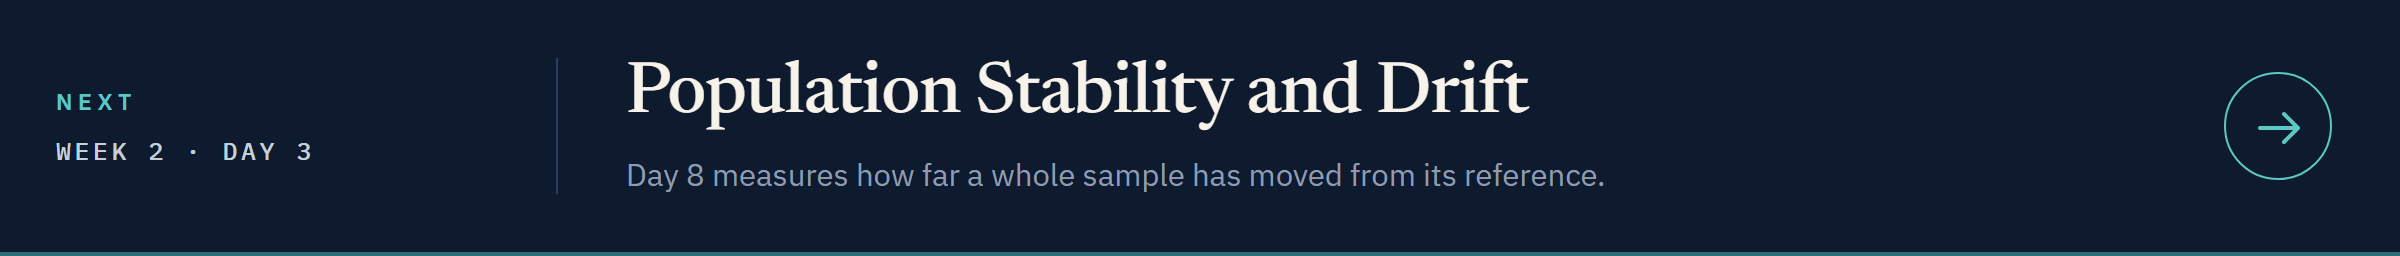](../day3/08_population_stability_and_drift.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week2/day3/08_population_stability_and_drift.ipynb)